# 07 · Synthetic data and the image-quality shortcut

The teammate's generator (Stable Diffusion 1.5 + LoRA) produced 4,000 normal and 1,000 pneumonia chest X-rays. E3/E4 add 250/500 of
them to the 1,000 real training images. This notebook shows **what those images are, why they hurt external performance, and what the
underlying shortcut is**. Every claim comes with a picture.

| § | Question | How it is shown |
|---|---|---|
| 1 | What do the synthetic images look like? | side-by-side with real Kermany |
| 2 | Do they help or hurt? | E3/E4 vs E1, real-data controls R25/R50, E2/E2_ERASE, per acquisition view |
| 3 | Do the labels carry pneumonia? | real-trained classifiers scoring the synthetic set |
| 4 | Which shortcut do they carry? | image-quality statistics per class, high-pass maps |
| 5 | Do models actually use it? | causal test: degrade healthy images, watch the score |
| 6 | Can preprocessing remove it? | histogram equalisation / low-pass, before vs after |
| 7 | Copies or new images? Which training set? | nearest real neighbour of every synthetic image |
| 8 | Does *more* synthetic data help? | 250 → 2,000 synthetic images, and synthetic images only |
| 9 | Is the shortcut visible in real external films? | each RSNA film's own sharpness, contrast and age vs the model score |
| 10 | Does choosing *which* synthetic images help? | quality-matched and quality-counter selections |
| 11 | Can the training loss remove it? | focal, GCE, group DRO, quality-consistency loss |

### Three different ways to change the training data

They are easy to mix up, and they behave very differently in this notebook:

| Term | What it is | Applied to | Runs |
|---|---|---|---|
| **Augmentation** | random transformations of the *same real images* (flip, rotation, brightness/contrast, erasing…), drawn fresh at every training step. Adds no new images, only variations | training only | **E2** (conventional), **E2_ERASE** (+ random erasing), E2_ACQ, E2_ROBUST, E2_MIX |
| **Synthetic data** | *new images* made by a generative model (here Stable Diffusion + LoRA), added to the training set as extra examples with their generation label | training only | **E3** (+250 synthetic), **E4** (+500 synthetic) |
| **Preprocessing** | a fixed, deterministic transformation of *every* image the model ever sees, training **and** test | everything | E1 etc. use `squash`; runs tagged **HARM** use `harmonize224` (§6) |

Reference runs: **E1** = the 1,000 real images, nothing added (baseline). **R25 / R50** = +250 / +500 *real* images instead of synthetic
ones (the fair control for E3/E4). Plots label each run with what it adds.

Heavy computations (classifier scores on 5,000 images, feature extraction) come from `scripts/synth_probe/*.py` (outputs in
`reports/results/synth_probe/`); everything visual is recomputed here on CPU. Main architecture: EfficientNet-B0 (the only one with
real-data controls R25/R50 and, so far, finished E3/E4 runs).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "reports/results"; RES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

import torch, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
from cxr.data import load_set, read_manifest, select, resolve
from cxr.imaging import load_gray, to_square
from cxr.engine import load_model, sigmoid, RUNS_DIR

CPU = torch.device("cpu"); torch.set_num_threads(4); torch.set_grad_enabled(False)  # inference only
SP = RES / "synth_probe"
A, B, S = "artifacts/manifests/kermany.csv", "artifacts/manifests/rsna.csv", "artifacts/manifests/synthetic_sd_lora.csv"
ARCH = "efficientnet_b0"
syn = load_set(S, None, 224, "squash", device=None)
kt = load_set(A, {"split": "train"}, 224, "squash", device=None)
rs = load_set(B, {"split": "external"}, 224, "squash", device=None)
RNG = np.random.default_rng(0)

def pick(ts, mask, n, rng=RNG):
    idx = np.sort(rng.choice(np.where(mask)[0], n, replace=False))
    return ts.images[idx][:, 0], ts.df.iloc[idx]

def grid(rows, titles=None, row_labels=None, size=2.0, cmap="gray"):
    nr, nc = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(nr, nc, figsize=(size * nc, size * nr), squeeze=False)
    for i, r in enumerate(rows):
        for j in range(nc):
            ax = axes[i, j]; ax.axis("off")
            if j < len(r):
                ax.imshow(r[j], cmap=cmap, vmin=0, vmax=255 if cmap == "gray" else None)
                if titles is not None and titles[i] is not None and j < len(titles[i]):
                    ax.set_title(titles[i][j], fontsize=8)
        if row_labels:
            axes[i, 0].text(-0.08, 0.5, row_labels[i], transform=axes[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
    plt.tight_layout()
    return fig

@torch.no_grad()
def score(model, imgs):
    x = torch.as_tensor(np.asarray(imgs), dtype=torch.float32).div(255)
    x = x[:, None] if x.ndim == 3 else x
    return sigmoid(model(x.contiguous(memory_format=torch.channels_last)).numpy())

print(f"synthetic {len(syn)} | Kermany train {len(kt)} | RSNA labelled (opacity vs normal) {len(rs)}")

# what each run adds to the 1,000 real training images (used for plot labels)
NAMES = {"E1": "E1\nbaseline", "R25": "R25\n+250 real", "R50": "R50\n+500 real",
         "E3_sd_lora": "E3\n+250 synth.", "E4_sd_lora": "E4\n+500 synth.", "E3": "E3\n+250 synth.", "E4": "E4\n+500 synth.",
         "E2": "E2\naugment.", "E2_ERASE": "E2_ERASE\naugm.+erase",
         "ERASE_REAL250": "ERASE\n+250 real", "ERASE_REAL500": "ERASE\n+500 real",
         "ERASE_SYN250_sd_lora": "ERASE\n+250 synth.", "ERASE_SYN500_sd_lora": "ERASE\n+500 synth.",
         "SYN1000_sd_lora": "+1,000\nsynth.", "SYN2000_sd_lora": "+2,000\nsynth.", "SYN_ONLY_sd_lora": "2,000 synth.\nonly"}
SHORT = {k: v.replace("\n", " · ") for k, v in NAMES.items()}

/home/edelweizse/Projects/uni/AIE/final/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


synthetic 5000 | Kermany train 4093 | RSNA labelled (opacity vs normal) 16896


## 1. What the synthetic images look like

One fixed prompt per class, 30 sampling steps, guidance 4.5, 512 × 512. Rows 1–2 are synthetic, rows 3–4 real Kermany training images
(all after the same 224 px full-FOV squash the classifier sees).

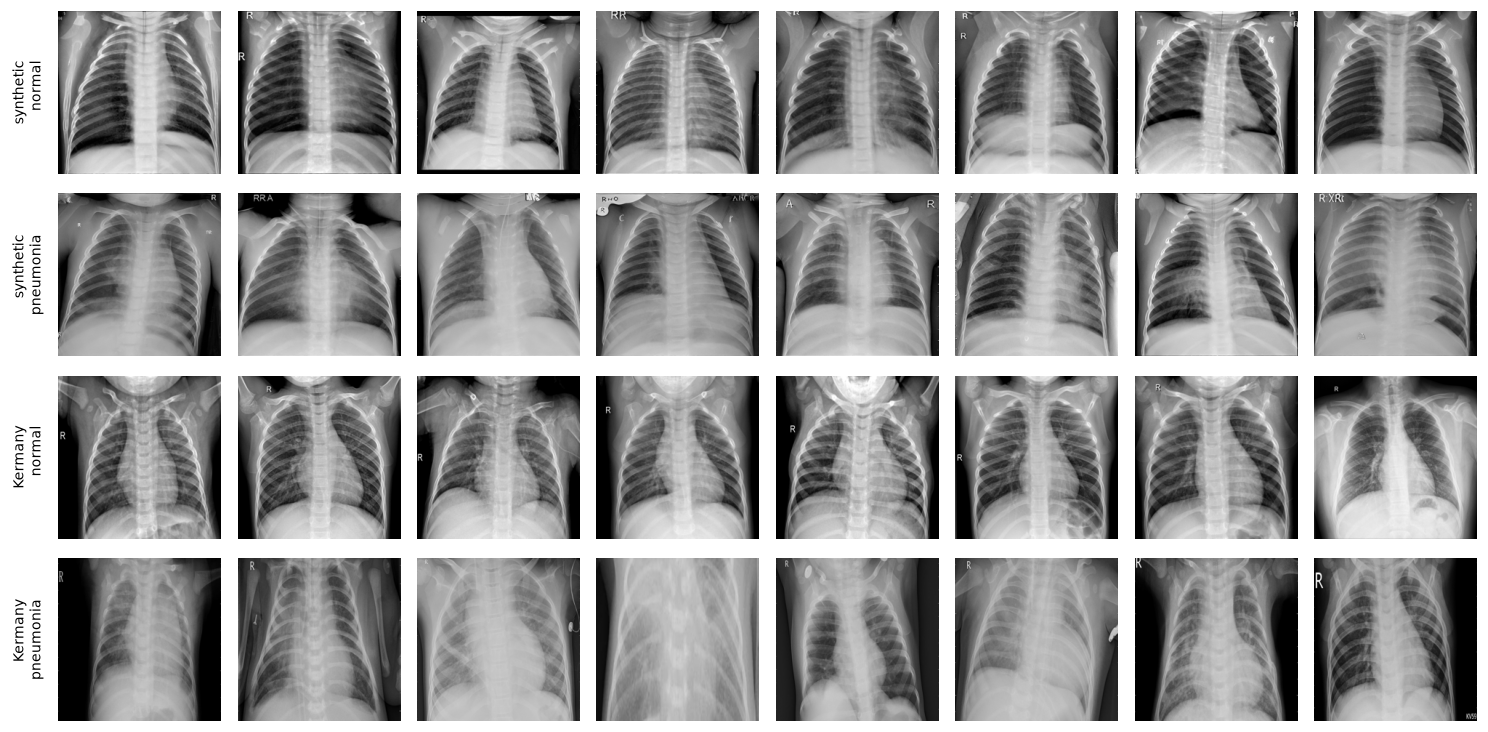

,n,prompt,steps,cfg
label,,,,
NORMAL,4000,"a frontal cxr_scan of normal lungs, clear lung...",30,4.5
PNEUMONIA,1000,"a frontal cxr_scan showing pneumonia, lung con...",30,4.5


In [2]:
sl, kl = syn.labels.numpy(), kt.labels.numpy()
rows, labels = [], []
for name, ts, lab in [("synthetic", syn, sl), ("Kermany", kt, kl)]:
    for c, cname in [(0, "normal"), (1, "pneumonia")]:
        rows.append(pick(ts, lab == c, 8, np.random.default_rng(1))[0]); labels.append(f"{name}\n{cname}")
fig = grid(rows, row_labels=labels, size=1.7); plt.savefig(FIG / "synth_montage.png", bbox_inches="tight"); plt.show()
m = pd.read_csv(ROOT / "data/synthetic/sd_lora/manifest.csv")
display(m.groupby("label").agg(n=("filename", "size"), prompt=("prompt", "first"), steps=("steps", "first"), cfg=("guidance_scale", "first")))

**What to notice.** The images are plausible pediatric radiographs with burned-in side markers, like Kermany. The two synthetic classes
look much more alike than the two real classes: real pneumonia images are visibly hazier, smaller and lower in contrast.

## 2. Do they help? Synthetic vs real images, with and without augmentation

All runs: the same 1,000 real images, step budget, early stopping, Optuna hyper-parameters, Kermany validation for checkpoint and threshold.
The question is asked twice, with the same structure each time (*baseline → + real images → + synthetic images*):

| Group | Baseline | + real images (control) | + synthetic images |
|---|---|---|---|
| **no augmentation** | E1 | R25 / R50 (+250 / +500 real) | E3 / E4 (+250 / +500 synthetic) |
| **with E2_ERASE augmentation** | E2_ERASE | ERASE_REAL250 / 500 | ERASE_SYN250 / 500 |

The second group asks the question a reviewer would ask: do synthetic images add anything on top of the *best* real-data recipe?
E2_ERASE is used as that recipe because it is the best variant on **RSNA-dev** for every architecture (notebook 06 variants re-scored on
the selection split). To keep that choice honest, RSNA is split by patient into **RSNA-dev** (30%, selection only) and **RSNA-test** (70%,
reporting); every number below is **RSNA-test**. Pooled AUROC partly rewards recognising the view (AP films carry far more opacity), so
within-view AUROC is shown as well.

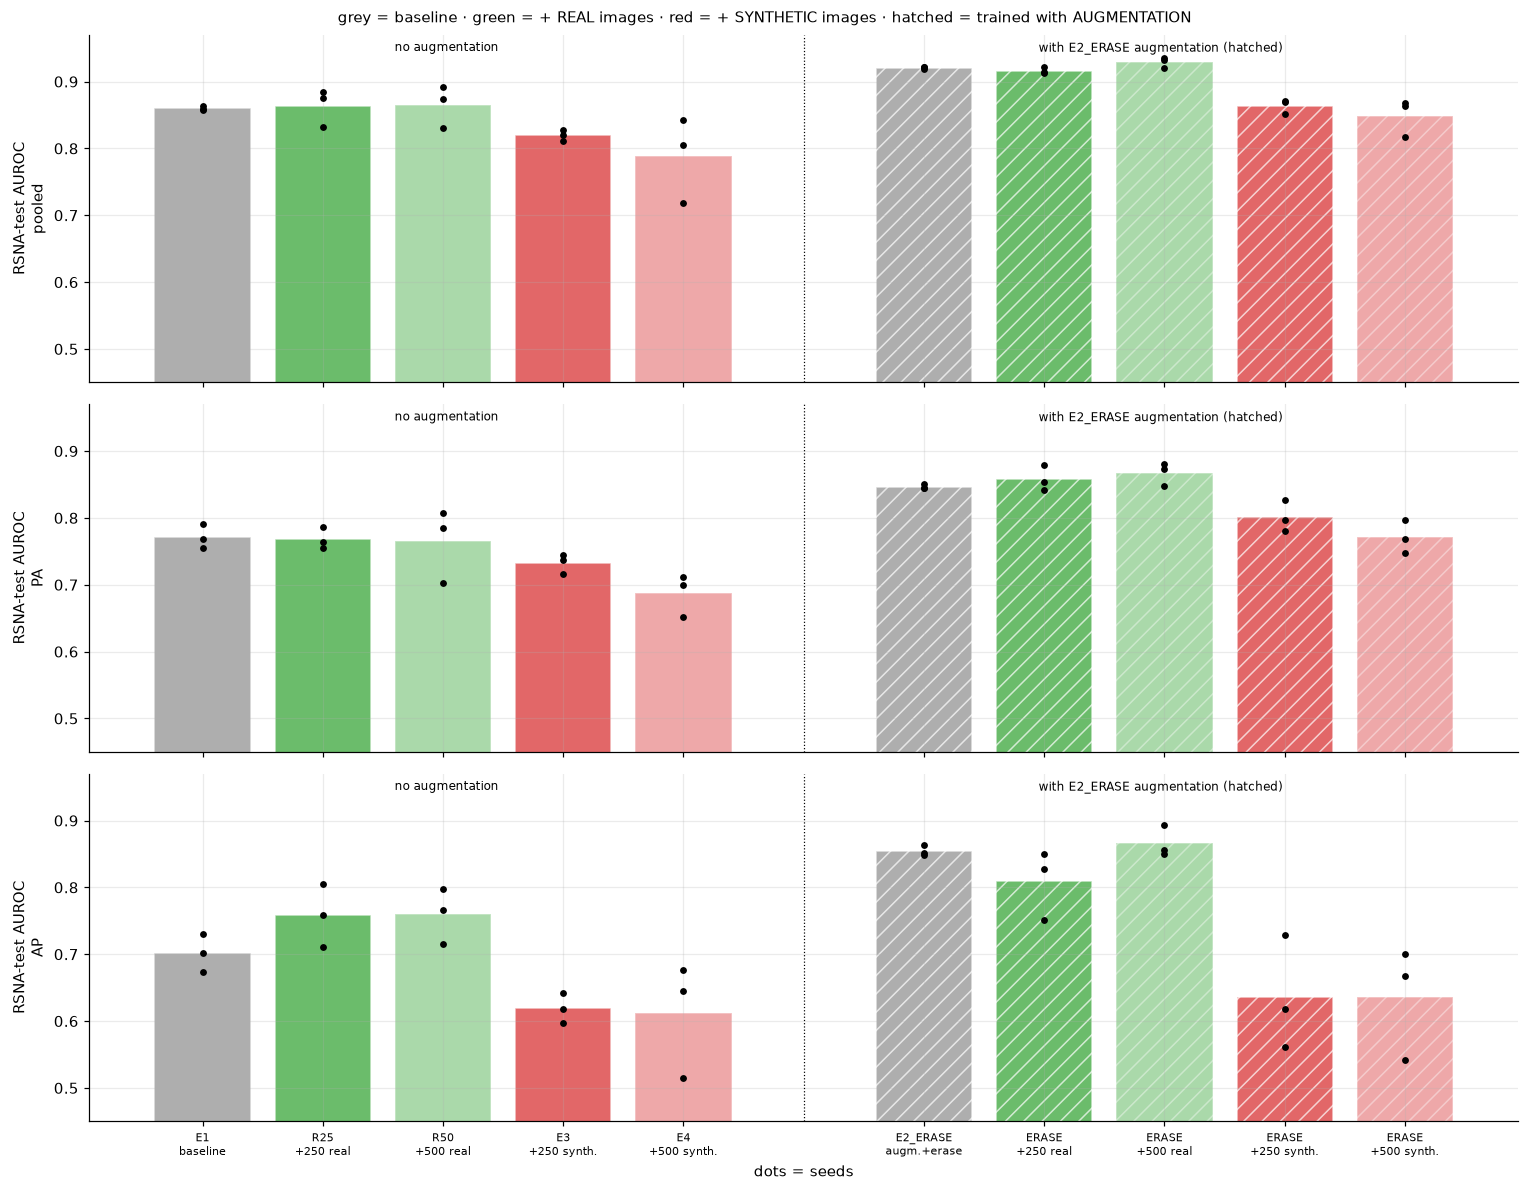

pooled                  PA                  AP              p_normal_PA              p_normal_AP             
                       mean    std count   mean    std count   mean    std count        mean    std count        mean    std count
experiment                                                                                                                        
E1                    0.860  0.004     3  0.771  0.018     3  0.701  0.028     3       0.324  0.129     3       0.828  0.134     3
R25                   0.863  0.028     3  0.768  0.017     3  0.758  0.047     3       0.253  0.091     3       0.714  0.044     3
R50                   0.866  0.032     3  0.765  0.055     3  0.760  0.041     3       0.195  0.096     3       0.604  0.273     3
E3_sd_lora            0.820  0.008     3  0.733  0.015     3  0.619  0.022     3       0.401  0.062     3       0.895  0.054     3
E4_sd_lora            0.789  0.064     3  0.688  0.032     3  0.612  0.085     3       0.465  0.141     3       0.935  0.052     3
E2_ERASE              0.921  0.002     3  0.847  0.004     3  0.855  0.008     3       0.138  0.032     3       0.726  0.043     3
ERASE_REAL250         0.916  0.004     3  0.858  0.019     3  0.810  0.052     3       0.188  0.102     3       0.806  0.136     3
ERASE_REAL500         0.929  0.008     3  0.867  0.017     3  0.867  0.024     3       0.064  0.030     3       0.592  0.062     3
ERASE_SYN250_sd_lora  0.864  0.010     3  0.801  0.023     3  0.636  0.085     3       0.287  0.270     3       0.819  0.110     3
ERASE_SYN500_sd_lora  0.849  0.028     3  0.771  0.025     3  0.636  0.084     3       0.458  0.199     3       0.897  0.056     3

In [3]:
from cxr.analysis import add_b_role
# two groups with the same structure: baseline | + real images | + synthetic images
GROUPS = {"no augmentation": ["E1", "R25", "R50", "E3_sd_lora", "E4_sd_lora"],
          "with E2_ERASE augmentation": ["E2_ERASE", "ERASE_REAL250", "ERASE_REAL500", "ERASE_SYN250_sd_lora", "ERASE_SYN500_sd_lora"]}
EXPS2 = [e for g in GROUPS.values() for e in g]
KIND = {"E1": "base", "E2_ERASE": "base", "R25": "real", "R50": "real", "ERASE_REAL250": "real", "ERASE_REAL500": "real",
        "E3_sd_lora": "syn", "E4_sd_lora": "syn", "ERASE_SYN250_sd_lora": "syn", "ERASE_SYN500_sd_lora": "syn"}
COL = {"base": "0.55", "real": "tab:green", "syn": "tab:red"}

def b_test_metrics(exp, arch=ARCH):
    out = []
    for seed in range(3):
        p = RUNS_DIR / exp / arch / f"seed{seed}" / "preds_B_external.csv"
        if not p.exists():
            continue
        d = add_b_role(pd.read_csv(p, dtype={"patient_id": str})); d = d[d.label.notna() & (d.b_role == "test")]
        r = {"experiment": exp, "arch": arch, "seed": seed, "pooled": roc_auc_score(d.label, d.prob)}
        for v in ("PA", "AP"):
            g = d[d.view == v]; r[v] = roc_auc_score(g.label, g.prob); r[f"p_normal_{v}"] = g[g.label == 0].prob.mean()
        out.append(r)
    return out

e34 = pd.DataFrame([r for e in EXPS2 for r in b_test_metrics(e)])
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
xs = {e: i + (1 if i >= len(GROUPS["no augmentation"]) else 0) for i, e in enumerate(EXPS2)}  # gap between groups
for ax, k in zip(axes, ["pooled", "PA", "AP"]):
    for e in EXPS2:
        v = e34[e34.experiment == e][k] if len(e34) else []
        if len(v):
            aug = e in GROUPS["with E2_ERASE augmentation"]
            ax.bar(xs[e], v.mean(), color=COL[KIND[e]], alpha=0.4 if e.endswith(("500", "500_sd_lora", "R50", "E4_sd_lora")) else 0.7,
                   hatch="//" if aug else None, edgecolor="white")
            ax.scatter([xs[e]] * len(v), v, color="k", s=12, zorder=3)
    ax.axvline(len(GROUPS["no augmentation"]), color="k", lw=0.8, ls=":")
    ax.set_xticks([xs[e] for e in EXPS2], [NAMES[e] for e in EXPS2], fontsize=7)
    ax.set_ylabel(f"RSNA-test AUROC\n{k}"); ax.set_ylim(0.45, 0.97)
    ax.text(0.25, 0.98, "no augmentation", transform=ax.transAxes, ha="center", va="top", fontsize=8)
    ax.text(0.75, 0.98, "with E2_ERASE augmentation (hatched)", transform=ax.transAxes, ha="center", va="top", fontsize=8)
axes[-1].set_xlabel("dots = seeds")
fig.suptitle("grey = baseline · green = + REAL images · red = + SYNTHETIC images · hatched = trained with AUGMENTATION", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "synth_e3e4_views.png", bbox_inches="tight"); plt.show()
display(e34.groupby("experiment")[["pooled", "PA", "AP", "p_normal_PA", "p_normal_AP"]].agg(["mean", "std", "count"]).reindex([e for e in EXPS2 if e in set(e34.experiment)]).round(3))

Where do the extra AP errors come from? The score distribution of **healthy** RSNA patients on AP films:

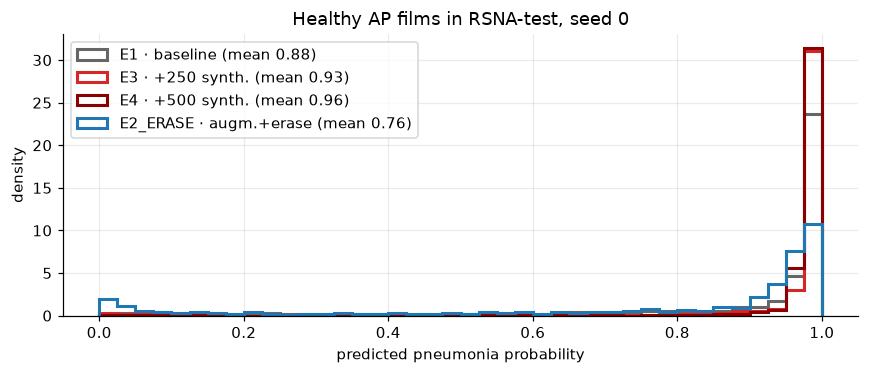

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for exp, c in [("E1", "0.4"), ("E3_sd_lora", "tab:red"), ("E4_sd_lora", "darkred"), ("E2_ERASE", "tab:blue")]:
    p = RUNS_DIR / exp / ARCH / "seed0" / "preds_B_external.csv"
    if p.exists():
        d = add_b_role(pd.read_csv(p, dtype={"patient_id": str})); d = d[(d.label == 0) & (d.view == "AP") & (d.b_role == "test")]
        ax.hist(d.prob, bins=40, range=(0, 1), histtype="step", lw=2, color=c, density=True, label=f"{SHORT[exp]} (mean {d.prob.mean():.2f})")
ax.set_xlabel("predicted pneumonia probability"); ax.set_ylabel("density"); ax.legend(); ax.set_title("Healthy AP films in RSNA-test, seed 0")
plt.tight_layout(); plt.savefig(FIG / "synth_ap_normals.png", bbox_inches="tight"); plt.show()

Is this specific to EfficientNet-B0? The augmented group was also run for ViT-S and DenseNet-121. Change in RSNA-test AUROC of the
3-seed ensemble relative to E2_ERASE, with a patient-clustered bootstrap 95% CI (`scripts/synth_probe/erase_compare.py`):

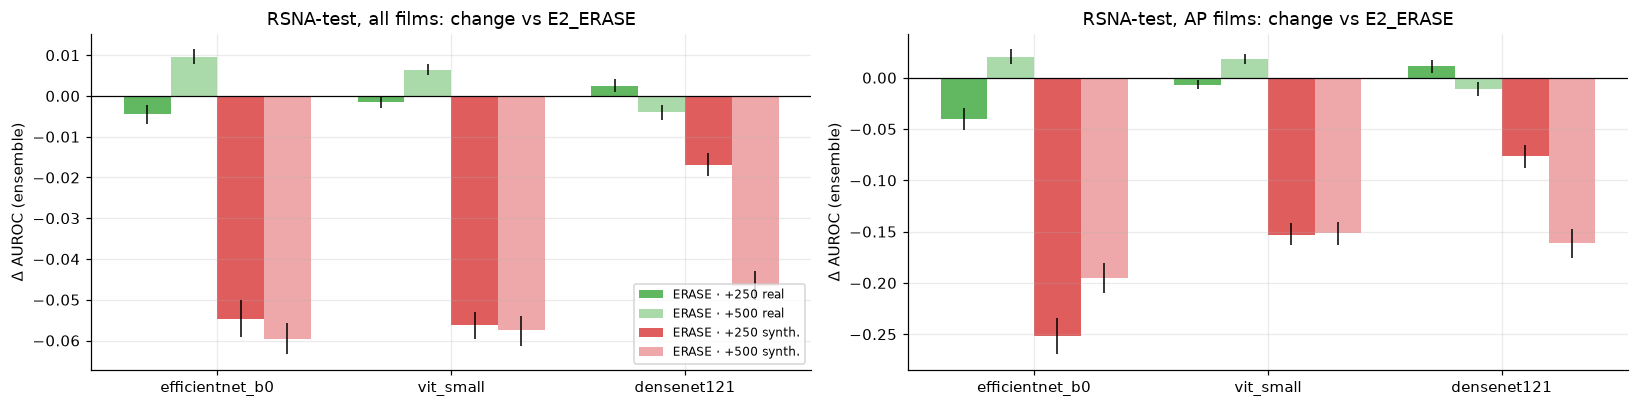

to                                 ERASE_REAL250  ERASE_REAL500  ERASE_SYN250_sd_lora  ERASE_SYN500_sd_lora
arch            eval                                                                                       
densenet121     rsna-test                  0.002         -0.004                -0.017                -0.047
                rsna-test&view=AP          0.011         -0.011                -0.077                -0.161
                rsna-test&view=PA         -0.002         -0.002                -0.008                -0.066
efficientnet_b0 rsna-test                 -0.004          0.010                -0.055                -0.060
                rsna-test&view=AP         -0.041          0.020                -0.252                -0.195
                rsna-test&view=PA          0.008          0.023                -0.038                -0.072
vit_small       rsna-test                 -0.002          0.006                -0.056                -0.057
                rsna-test&view=AP         -0.007          0.018                -0.153                -0.152
                rsna-test&view=PA          0.001          0.012                -0.083                -0.100

In [5]:
ec = pd.read_csv(SP / "erase_compare.csv"); ec = ec[ec["from"] == "E2_ERASE"]
TO = ["ERASE_REAL250", "ERASE_REAL500", "ERASE_SYN250_sd_lora", "ERASE_SYN500_sd_lora"]
ARCHS3 = ["efficientnet_b0", "vit_small", "densenet121"]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=False)
for ax, ev, nm in [(axes[0], "rsna-test", "all films"), (axes[1], "rsna-test&view=AP", "AP films")]:
    for k, to in enumerate(TO):
        g = ec[(ec.to == to) & (ec["eval"] == ev)].set_index("arch").reindex(ARCHS3)
        x = np.arange(len(ARCHS3)) + (k - 1.5) * 0.2
        ax.bar(x, g.delta_ensemble, 0.2, color=COL[KIND[to]], alpha=0.4 if to.endswith(("500", "500_sd_lora")) else 0.75, label=SHORT[to])
        ax.errorbar(x, g.delta_ensemble, yerr=[g.delta_ensemble - g.ci_lo, g.ci_hi - g.delta_ensemble], fmt="none", ecolor="k", lw=1)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(ARCHS3)), ARCHS3)
    ax.set_title(f"RSNA-test, {nm}: change vs E2_ERASE"); ax.set_ylabel("Δ AUROC (ensemble)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "synth_erase_archs.png", bbox_inches="tight"); plt.show()
display(ec.pivot_table(index=["arch", "eval"], columns="to", values="delta_ensemble").round(3))

**What to notice.** Extra *real* images change nothing on top of augmentation (|Δ| ≤ 0.01): the augmented model has taken what more
Kermany-like data can give. Extra *synthetic* images cost 0.02–0.06 for all three architectures, and on AP films they take EfficientNet-B0
from 0.88 to 0.63, below the un-augmented E1 (0.75). Augmentation does not protect against synthetic images; the penalty is as large as
without it, or larger.

## 3. Do the synthetic labels carry pneumonia?

Classifiers trained only on real images score all 5,000 synthetic images. If the generator learned pneumonia, synthetic "pneumonia"
should score high and synthetic "normal" low. Comparing a naive model (E1) with the most shortcut-resistant one (E2_ERASE) shows how much
of that signal survives when shortcuts are harder to use.

auroc_synth  auroc_realval  p_synth_normal  p_synth_pneu  p_real_normal  p_real_pneu
arch            exp                                                                                           
efficientnet_b0 E1              0.904          0.999           0.225         0.796          0.043        0.985
                E2              0.902          0.998           0.046         0.506          0.024        0.969
                E2_ERASE        0.913          0.999           0.050         0.544          0.054        0.975
densenet121     E1              0.858          0.999           0.307         0.793          0.038        0.984
                E2              0.867          0.998           0.257         0.759          0.046        0.977
                E2_ERASE        0.749          0.998           0.064         0.280          0.058        0.978
vit_small       E1              0.862          0.994           0.089         0.522          0.057        0.970
                E2              0.861          0.997           0.039         0.357          0.036        0.963
                E2_ERASE        0.833          0.997           0.056         0.289          0.047        0.957

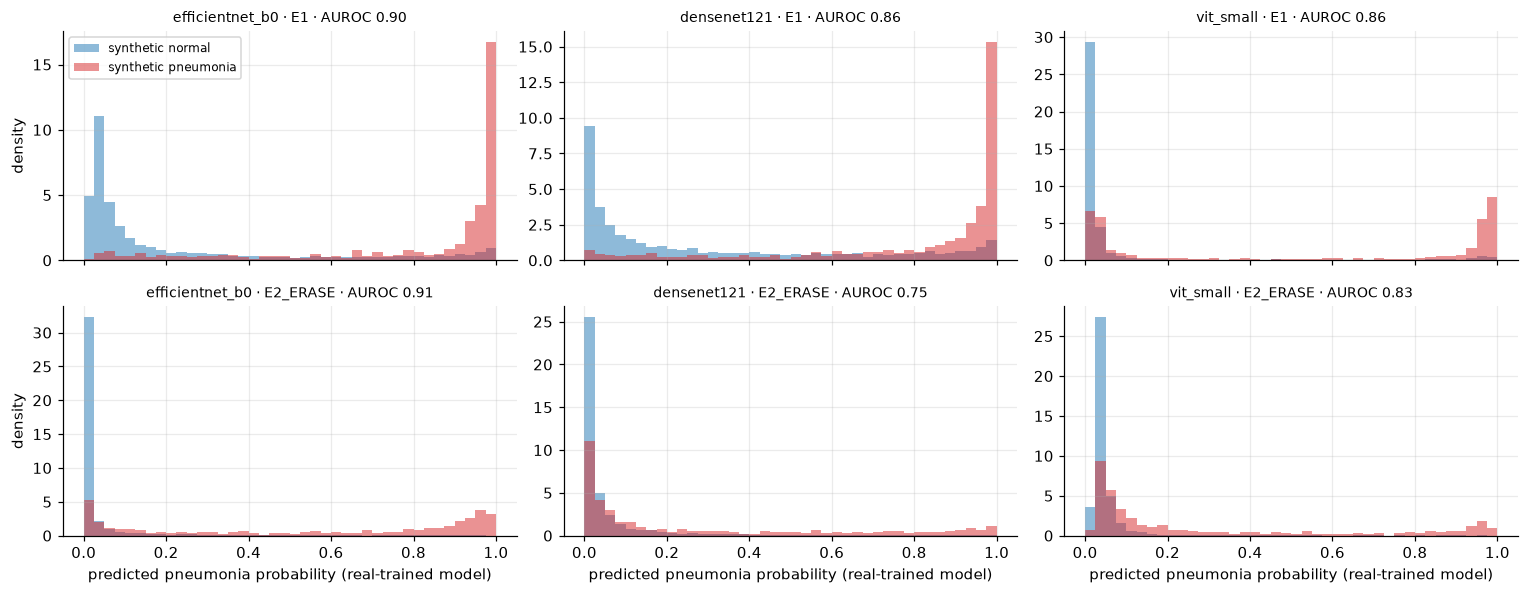

In [6]:
ls = pd.read_csv(SP / "label_signal.csv")
display(ls.set_index(["arch", "exp"]).round(3))
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5), sharex=True)
for j, arch in enumerate(["efficientnet_b0", "densenet121", "vit_small"]):
    for i, exp in enumerate(["E1", "E2_ERASE"]):
        d = pd.read_csv(SP / f"pred_{exp}_{arch}.csv"); c = d.columns[-1]; ax = axes[i, j]
        for lab, color, name in [(0, "tab:blue", "synthetic normal"), (1, "tab:red", "synthetic pneumonia")]:
            ax.hist(d[d.label == lab][c], bins=40, range=(0, 1), density=True, alpha=0.5, color=color, label=name)
        ax.set_title(f"{arch} · {exp} · AUROC {roc_auc_score(d.label, d[c]):.2f}", fontsize=9)
        if j == 0: ax.set_ylabel("density")
axes[0, 0].legend(fontsize=8)
for ax in axes[1]: ax.set_xlabel("predicted pneumonia probability (real-trained model)")
plt.tight_layout(); plt.savefig(FIG / "synth_label_signal.png", bbox_inches="tight"); plt.show()

Which synthetic "pneumonia" images does the robust model believe, and which not? Top row: the 8 the E2_ERASE DenseNet scores
**highest**; bottom row: the 8 it scores **lowest**.

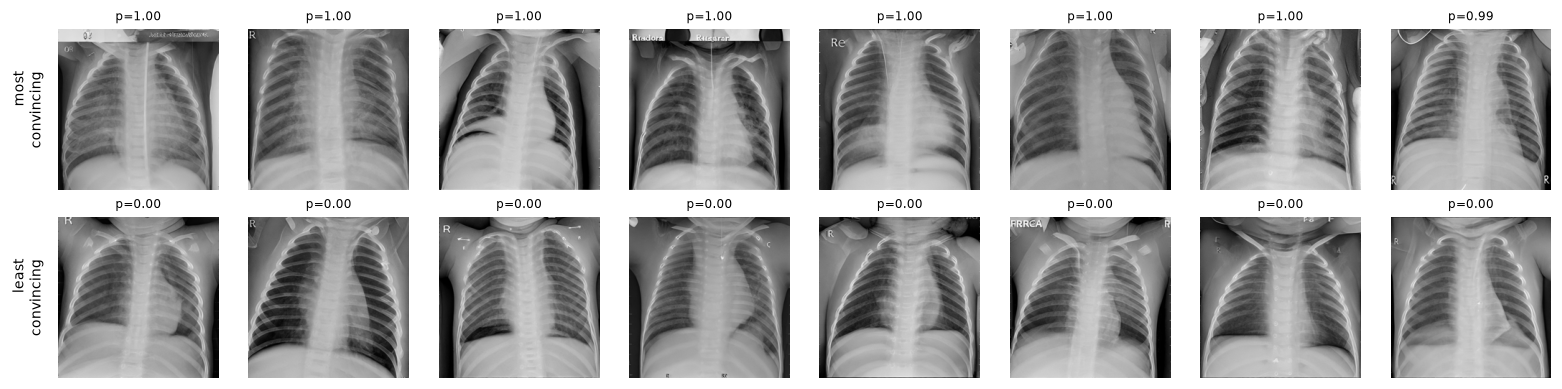

In [7]:
d = pd.read_csv(SP / "pred_E2_ERASE_densenet121.csv"); c = d.columns[-1]
d = d[d.label == 1].sort_values(c)
pos = {iid: i for i, iid in enumerate(syn.df.image_id)}
rows, titles = [], []
for ids in [d.image_id.iloc[::-1][:8], d.image_id[:8]]:
    idx = [pos[i] for i in ids]
    rows.append(syn.images[np.array(idx)][:, 0]); titles.append([f"p={v:.2f}" for v in d.set_index("image_id").loc[ids, c]])
grid(rows, titles, ["most\nconvincing", "least\nconvincing"], size=1.8); plt.savefig(FIG / "synth_pneu_extremes.png", bbox_inches="tight"); plt.show()

## 4. The shortcut they carry: image quality

Three simple statistics at the training resolution: **sharpness** (mean absolute high-frequency residual), **Laplacian variance**,
and **contrast** (pixel SD in the central crop). The table gives the AUROC of a *low* value predicting pneumonia: 0.5 means the statistic
says nothing about the label.

,sharpness,Laplacian var,contrast
group,,,
kermany_train,0.865,0.799,0.749
rsna AP,0.555,0.530,0.629
rsna PA,0.560,0.468,0.504
synthetic,0.861,0.776,0.889


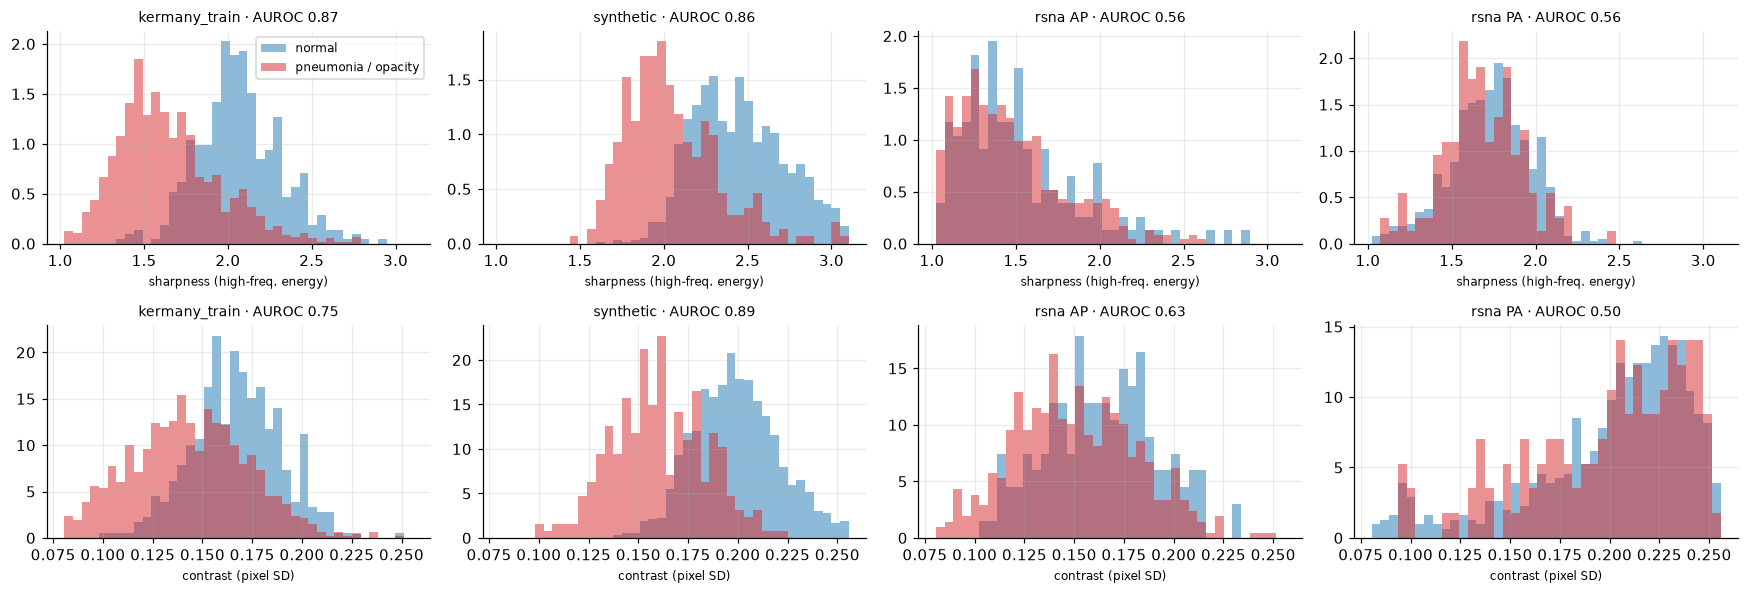

In [8]:
tx = pd.read_csv(SP / "texture.csv")
tx["group"] = tx["set"] + np.where(tx["view"].isin(["AP", "PA"]), " " + tx["view"].astype(str), "")
sc = tx.groupby("group").apply(lambda g: pd.Series({c: roc_auc_score(g.label, -g[c]) for c in ["hf_energy", "lap_var", "std"]}))
display(sc.rename(columns={"hf_energy": "sharpness", "lap_var": "Laplacian var", "std": "contrast"}).round(3))
fig, axes = plt.subplots(2, 4, figsize=(16, 5.5))
for i, (stat, name) in enumerate([("hf_energy", "sharpness (high-freq. energy)"), ("std", "contrast (pixel SD)")]):
    for j, grp in enumerate(["kermany_train", "synthetic", "rsna AP", "rsna PA"]):
        g = tx[tx.group == grp]; ax = axes[i, j]
        lo, hi = tx[stat].quantile([0.01, 0.99])
        for lab, color, nm in [(0, "tab:blue", "normal"), (1, "tab:red", "pneumonia / opacity")]:
            ax.hist(g[g.label == lab][stat], bins=40, range=(lo, hi), density=True, alpha=0.5, color=color, label=nm)
        ax.set_title(f"{grp} · AUROC {roc_auc_score(g.label, -g[stat]):.2f}", fontsize=9); ax.set_xlabel(name, fontsize=8)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "synth_quality_stats.png", bbox_inches="tight"); plt.show()

**What the statistic sees.** High-pass residual maps (image minus a 5 px box blur) of typical images: bright = fine detail. Real and
synthetic pneumonia images have visibly less fine structure than their normals, while in RSNA the two classes look alike.

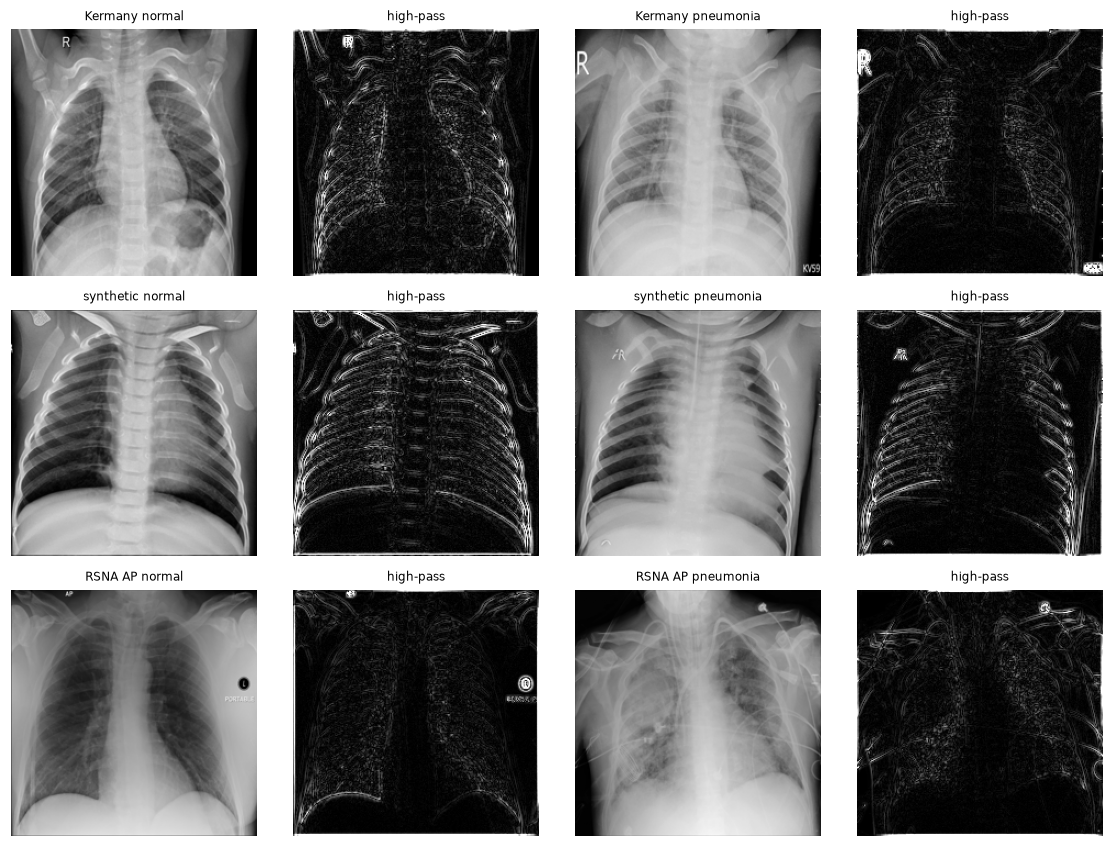

In [9]:
def highpass(img):
    x = torch.as_tensor(img, dtype=torch.float32)[None, None] / 255
    return (x - F.avg_pool2d(x, 5, 1, 2)).abs()[0, 0].numpy()

def median_example(ts, lab_arr, lab, stat_df, group, extra=None):
    # the image whose sharpness is closest to its class median: typical, not cherry-picked
    mask = lab_arr == lab if extra is None else (lab_arr == lab) & extra
    cand = np.where(mask)[0][:400]
    hp = np.array([highpass(ts.images[np.array([k])][0, 0]).mean() * 100 for k in cand])
    k = cand[np.argmin(np.abs(hp - np.median(hp)))]
    return ts.images[np.array([k])][0, 0]

rl, rv = rs.labels.numpy(), rs.df["view"].to_numpy()
ex = [("Kermany", kt, kl, None), ("synthetic", syn, sl, None), ("RSNA AP", rs, rl, rv == "AP")]
rows, titles = [], []
for name, ts, lab, extra in ex:
    ims = [median_example(ts, lab, c, tx, name, extra) for c in (0, 1)]
    rows.append([ims[0], highpass(ims[0]) * 255 * 6, ims[1], highpass(ims[1]) * 255 * 6])
    titles.append([f"{name} normal", "high-pass", f"{name} pneumonia", "high-pass"])
grid(rows, titles, size=2.6); plt.savefig(FIG / "synth_highpass.png", bbox_inches="tight"); plt.show()

**Reading.** In Kermany, softness and low contrast alone predict pneumonia (AUROC 0.87 / 0.75). The generator reproduces the softness
cue almost exactly and makes the contrast cue *stronger* (0.89). In RSNA both are close to chance. So every synthetic image is one more
training example of "soft, low-contrast image = pneumonia", a rule that does not hold in the external data.

## 5. Do the models actually use it? A causal test

Correlation is not use. Here the **same healthy images** are degraded (Gaussian blur, reduced contrast) and nothing else changes. If a
model relies on image quality, its pneumonia score rises. First, one image so the effect is visible: a healthy image that all three
models score below 0.3 when clean (the median such image out of 60 random ones). Titles give each model's pneumonia probability:
**baseline** = E1, **augm.** = E2_ERASE (augmentation of real images), **+synth** = E3 (+250 synthetic images).

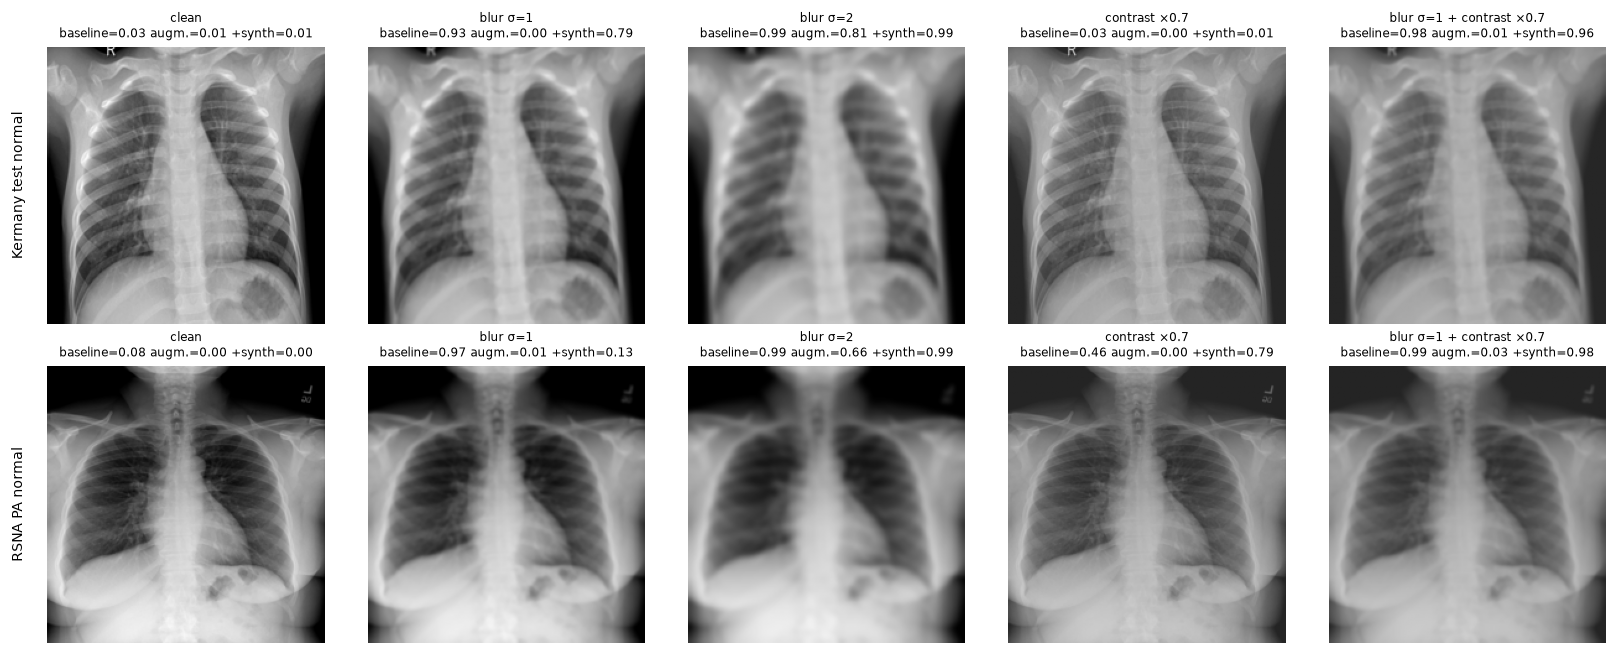

In [10]:
def gauss(x, sigma):
    k = int(2 * round(3 * sigma) + 1); t = torch.arange(k, dtype=torch.float32) - k // 2
    g = torch.exp(-t ** 2 / (2 * sigma ** 2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), g.view(1, 1, 1, k))
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), g.view(1, 1, k, 1))

def contrast(x, f):
    m = x.mean((2, 3), keepdim=True); return (m + f * (x - m)).clamp(0, 1)

DEGR = {"clean": lambda x: x, "blur σ=1": lambda x: gauss(x, 1.0), "blur σ=2": lambda x: gauss(x, 2.0),
        "contrast ×0.7": lambda x: contrast(x, 0.7), "blur σ=1 + contrast ×0.7": lambda x: contrast(gauss(x, 1.0), 0.7)}
MODELS = {e: load_model(RUNS_DIR / e / ARCH / "seed0", CPU)[0] for e in ["E1", "E2_ERASE", "E3_sd_lora"]}

al = load_set(A, {"split": "test"}, 224, "squash", device=None)
def typical_normal(ts, mask, rng):
    # a healthy image that all three models call healthy when clean (median score among those): typical, not cherry-picked on the effect
    imgs, _ = pick(ts, mask, 60, rng)
    p = np.max([score(m, imgs) for m in MODELS.values()], axis=0)
    ok = np.where(p < 0.3)[0]
    return imgs[ok[np.argsort(p[ok])[len(ok) // 2]]] if len(ok) else imgs[np.argmin(p)]

demo = [("Kermany test normal", typical_normal(al, al.labels.numpy() == 0, np.random.default_rng(3))),
        ("RSNA PA normal", typical_normal(rs, (rl == 0) & (rv == "PA"), np.random.default_rng(3)))]
LBL = {"E1": "baseline", "E2_ERASE": "augm.", "E3_sd_lora": "+synth"}
rows, titles = [], []
for name, img in demo:
    x = torch.as_tensor(img, dtype=torch.float32)[None, None] / 255
    ims, tt = [], []
    for dn, fn in DEGR.items():
        y = fn(x); ims.append((y[0, 0].numpy() * 255).astype(np.uint8))
        ps = {e: float(sigmoid(m(y.contiguous(memory_format=torch.channels_last)).numpy())[0]) for e, m in MODELS.items()}
        tt.append(f"{dn}\n" + " ".join(f"{LBL[e]}={p:.2f}" for e, p in ps.items()))
    rows.append(ims); titles.append(tt)
grid(rows, titles, [n for n, _ in demo], size=3.0); plt.savefig(FIG / "synth_degrade_demo.png", bbox_inches="tight"); plt.show()

Averaged over many healthy images (234 Kermany test normals, 300 RSNA PA and 300 AP normals; 2 seeds each, from `scripts/synth_probe/degrade.py`):

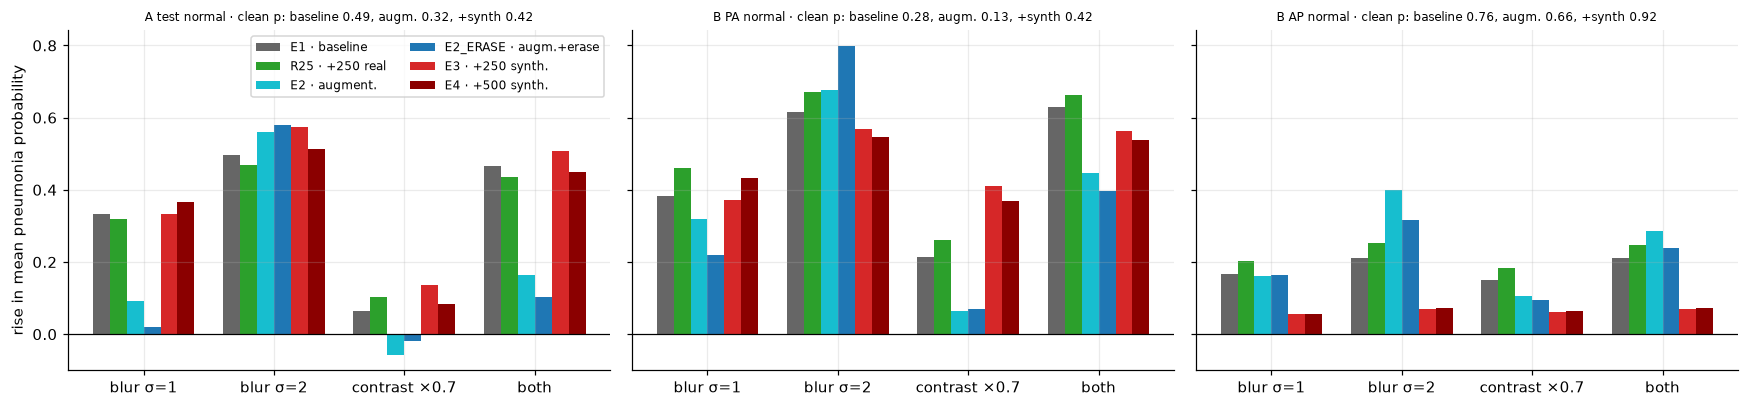

degr                      blur1  blur1+contrast0.7  blur2  contrast0.7  clean_p
set           exp                                                              
A_test_normal E1          0.332              0.466  0.496        0.064    0.488
              E2          0.091              0.163  0.559       -0.056    0.340
              E2_ERASE    0.020              0.104  0.581       -0.020    0.321
              E3_sd_lora  0.333              0.508  0.573        0.137    0.418
              E4_sd_lora  0.367              0.451  0.514        0.083    0.473
              R25         0.320              0.436  0.469        0.104    0.514
B_AP_normal   E1          0.167              0.211  0.211        0.150    0.764
              E2          0.162              0.285  0.401        0.105    0.540
              E2_ERASE    0.164              0.240  0.316        0.096    0.663
              E3_sd_lora  0.057              0.069  0.070        0.060    0.922
              E4_sd_lora  0.056              0.072  0.074        0.065    0.907
              R25         0.204              0.247  0.253        0.184    0.727
B_PA_normal   E1          0.383              0.629  0.615        0.213    0.276
              E2          0.318              0.446  0.677        0.063    0.135
              E2_ERASE    0.220              0.395  0.800        0.070    0.132
              E3_sd_lora  0.372              0.564  0.570        0.409    0.420
              E4_sd_lora  0.433              0.538  0.545        0.369    0.438
              R25         0.459              0.662  0.671        0.261    0.302

In [11]:
dg = pd.read_csv(SP / "degrade.csv")
t = dg.groupby(["set", "exp", "degr"]).mean_p.mean().unstack()
delta = t.sub(t["clean"], axis=0).drop(columns="clean")
order = ["E1", "R25", "E2", "E2_ERASE", "E3_sd_lora", "E4_sd_lora"]
colors = {"E1": "0.4", "R25": "tab:green", "E2": "tab:cyan", "E2_ERASE": "tab:blue", "E3_sd_lora": "tab:red", "E4_sd_lora": "darkred"}
sets = ["A_test_normal", "B_PA_normal", "B_AP_normal"]
degrs = ["blur1", "blur2", "contrast0.7", "blur1+contrast0.7"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
w = 0.13
for ax, s in zip(axes, sets):
    for k, exp in enumerate(order):
        v = delta.loc[(s, exp), degrs]
        ax.bar(np.arange(len(degrs)) + (k - 2.5) * w, v, w, color=colors[exp], label=SHORT[exp])
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(degrs)), ["blur σ=1", "blur σ=2", "contrast ×0.7", "both"])
    ax.set_title(f"{s.replace('_', ' ')} · clean p: " + ", ".join(f"{LBL[e]} {t.loc[(s, e), 'clean']:.2f}" for e in ["E1", "E2_ERASE", "E3_sd_lora"]), fontsize=8)
axes[0].set_ylabel("rise in mean pneumonia probability"); axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "synth_degrade.png", bbox_inches="tight"); plt.show()
display(delta.round(3).assign(clean_p=t["clean"].round(3)))

## 6. Can preprocessing remove the shortcut?

`harmonize<F>` (in `cxr/imaging.py`): squash → area-downsample to a common resolution floor *F* (also averages out noise) → global
histogram equalisation → resize to 224. Deblurring is deliberately not used: it invents detail and amplifies noise, a new artifact for
the model to learn. First what the transform does to an image:

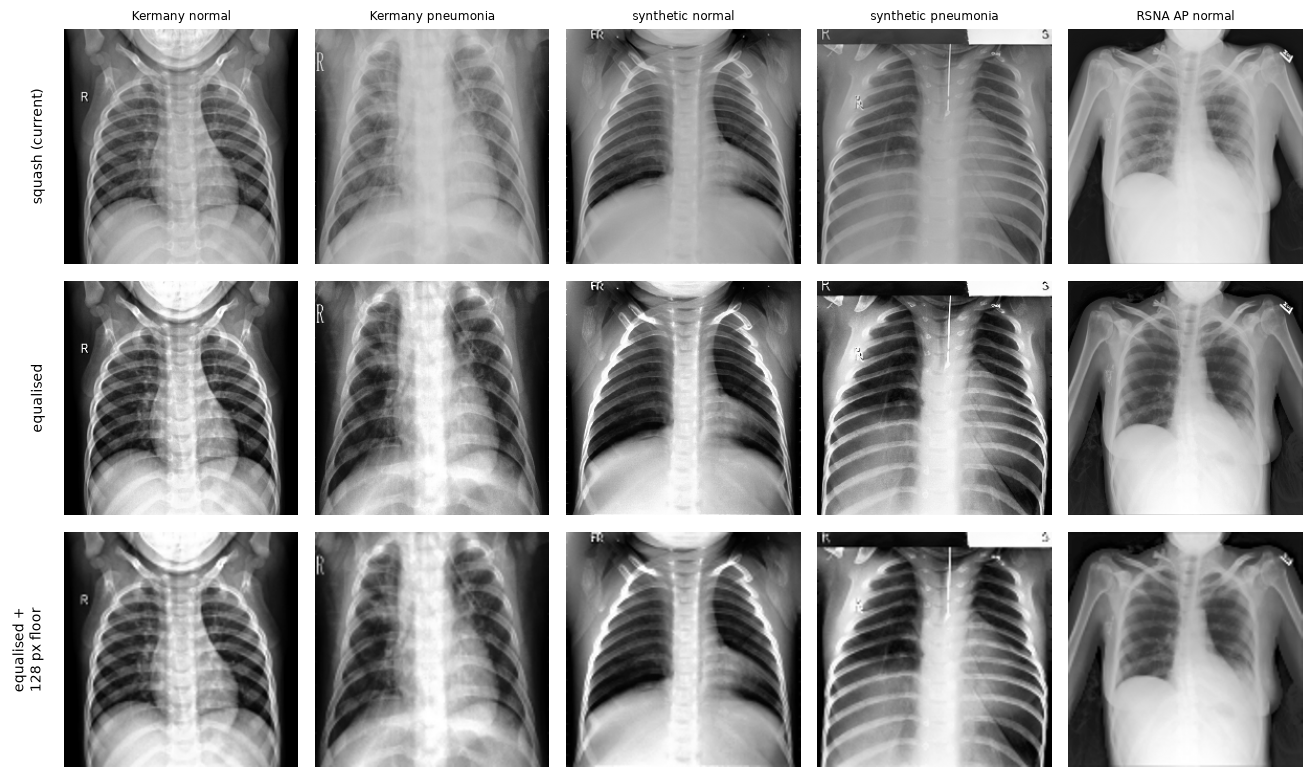

In [12]:
def from_file(ts, i, mode):
    return to_square(load_gray(resolve(ts.df.image_path.iloc[i])), 224, mode)

modes = ["squash", "harmonize224", "harmonize128"]
cases = [("Kermany normal", kt, np.where(kl == 0)[0][5]), ("Kermany pneumonia", kt, np.where(kl == 1)[0][5]),
         ("synthetic normal", syn, np.where(sl == 0)[0][5]), ("synthetic pneumonia", syn, np.where(sl == 1)[0][5]),
         ("RSNA AP normal", rs, np.where((rl == 0) & (rv == "AP"))[0][5])]
rows = [[from_file(ts, i, m) for _, ts, i in cases] for m in modes]
grid(rows, [[c for c, _, _ in cases]] + [None, None], ["squash (current)", "equalised", "equalised +\n128 px floor"], size=2.4)
plt.savefig(FIG / "synth_harmonize_demo.png", bbox_inches="tight"); plt.show()

Does it remove the cue? Label-predictiveness of each statistic after the transform (max(AUROC, 1 − AUROC), 800 images per set;
`scripts/synth_probe/harm_check.py`):

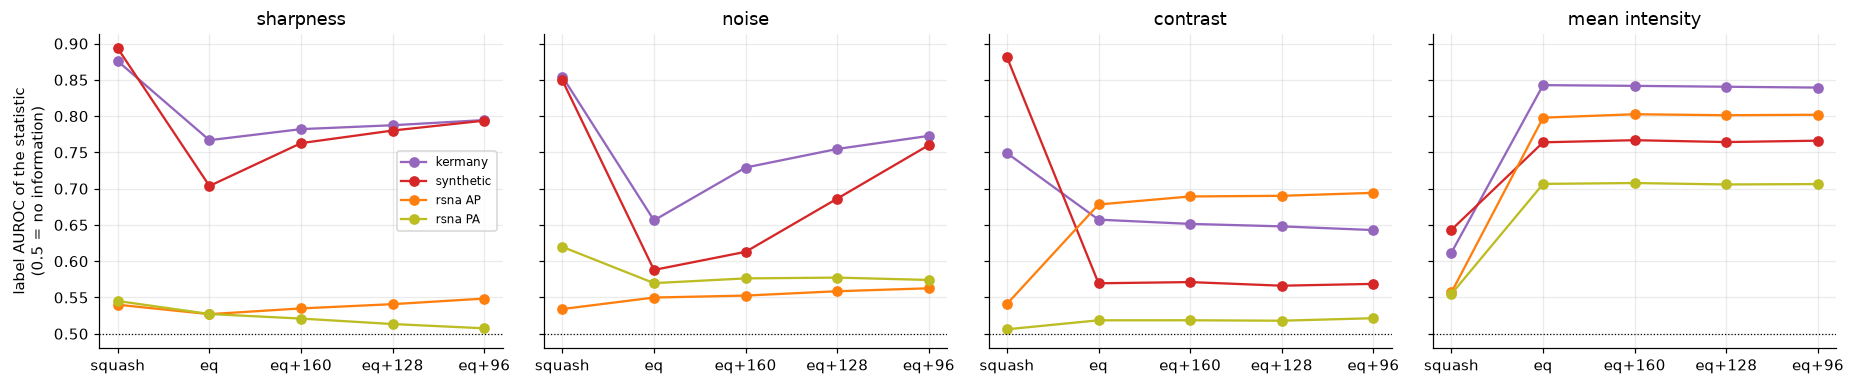

hf                             noise                               std                              mean                          
group        kermany rsna AP rsna PA synthetic kermany rsna AP rsna PA synthetic kermany rsna AP rsna PA synthetic kermany rsna AP rsna PA synthetic
mode                                                                                                                                                
harmonize128   0.787   0.541   0.513     0.780   0.755   0.559   0.577     0.686   0.648   0.690   0.518     0.566   0.840   0.801   0.706     0.764
harmonize160   0.782   0.535   0.521     0.763   0.729   0.553   0.576     0.613   0.651   0.689   0.519     0.571   0.842   0.803   0.708     0.767
harmonize224   0.767   0.527   0.527     0.704   0.656   0.550   0.570     0.588   0.657   0.678   0.519     0.570   0.843   0.798   0.707     0.764
harmonize96    0.795   0.549   0.508     0.794   0.773   0.563   0.574     0.760   0.643   0.694   0.521     0.569   0.839   0.802   0.706     0.766
squash         0.876   0.540   0.545     0.893   0.854   0.534   0.620     0.849   0.749   0.541   0.506     0.881   0.612   0.557   0.555     0.643

In [13]:
hc = pd.read_csv(SP / "harm_check.csv")
hc["group"] = hc["set"] + np.where(hc["view"].isin(["AP", "PA"]), " " + hc["view"].astype(str), "")
sc = hc.groupby(["mode", "group"]).apply(lambda g: pd.Series({c: max(roc_auc_score(g.label, g[c]), 1 - roc_auc_score(g.label, g[c]))
                                                            for c in ["hf", "noise", "std", "mean"]}))
modes = ["squash", "harmonize224", "harmonize160", "harmonize128", "harmonize96"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, (stat, nm) in zip(axes, [("hf", "sharpness"), ("noise", "noise"), ("std", "contrast"), ("mean", "mean intensity")]):
    for grp, c in [("kermany", "tab:purple"), ("synthetic", "tab:red"), ("rsna AP", "tab:orange"), ("rsna PA", "tab:olive")]:
        ax.plot(range(len(modes)), [sc.loc[(m, grp), stat] for m in modes], marker="o", color=c, label=grp)
    ax.axhline(0.5, color="k", lw=0.8, ls=":"); ax.set_title(nm)
    ax.set_xticks(range(len(modes)), ["squash", "eq", "eq+160", "eq+128", "eq+96"])
axes[0].set_ylabel("label AUROC of the statistic\n(0.5 = no information)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "synth_harmonize_stats.png", bbox_inches="tight"); plt.show()
display(sc.unstack("group").round(3))

**Reading.**
* **Equalisation is the part that works.** It cuts the synthetic contrast cue from 0.88 to 0.57 and lowers sharpness on both Kermany and
  synthetic. Lowering the resolution floor does *not* help further: at 96 px the sharpness cue is back to 0.79–0.80.
* **Part of the Kermany sharpness cue is not image quality.** It survives downsampling far below both classes' native resolution, so it
  is image *content*: Kermany pneumonia patients are probably younger and smaller (their images are smaller too). No filter removes that.
* **Side effect:** after equalisation, mean intensity predicts opacity in RSNA (≈0.80 AP, 0.71 PA). Equalisation makes real opacity
  stand out, which might help transfer by itself.

Whether this helps a trained classifier is tested directly, in two rounds. **HARM**: E1, E2, E2_ERASE, E3, E4 and the augmented
synthetic runs retrained on `harmonize224` images with the hyper-parameters tuned for standard preprocessing. **HARMT**: Optuna re-run
for `harmonize224` (25 trials, same search space and Kermany-validation objective), then E1, E2_ERASE, E3, E4 retrained. The second round
matters: comparing against an untuned harmonised baseline makes the synthetic images look harmless when they are not.

pooled           PA           AP      
                                           mean count   mean count   mean count
base         preprocessing                                                     
E1           standard                     0.860     3  0.771     3  0.701     3
             equalised (HARM)             0.826     3  0.765     3  0.716     3
             equalised, re-tuned (HARMT)  0.871     3  0.791     3  0.740     3
E2           standard                     0.915     3  0.840     3  0.826     3
             equalised (HARM)             0.901     3  0.823     3  0.801     3
E2_ERASE     standard                     0.921     3  0.847     3  0.855     3
             equalised (HARM)             0.901     3  0.825     3  0.814     3
             equalised, re-tuned (HARMT)  0.897     3  0.822     3  0.781     3
E3           standard                     0.820     3  0.733     3  0.619     3
             equalised (HARM)             0.833     3  0.738     3  0.650     3
             equalised, re-tuned (HARMT)  0.843     3  0.756     3  0.668     3
E4           standard                     0.789     3  0.688     3  0.612     3
             equalised (HARM)             0.838     3  0.740     3  0.666     3
             equalised, re-tuned (HARMT)  0.837     3  0.738     3  0.648     3
ERASE_SYN250 standard                     0.864     3  0.801     3  0.636     3
             equalised (HARM)             0.835     3  0.772     3  0.636     3
ERASE_SYN500 standard                     0.849     3  0.771     3  0.636     3
             equalised (HARM)             0.798     3  0.716     3  0.602     3

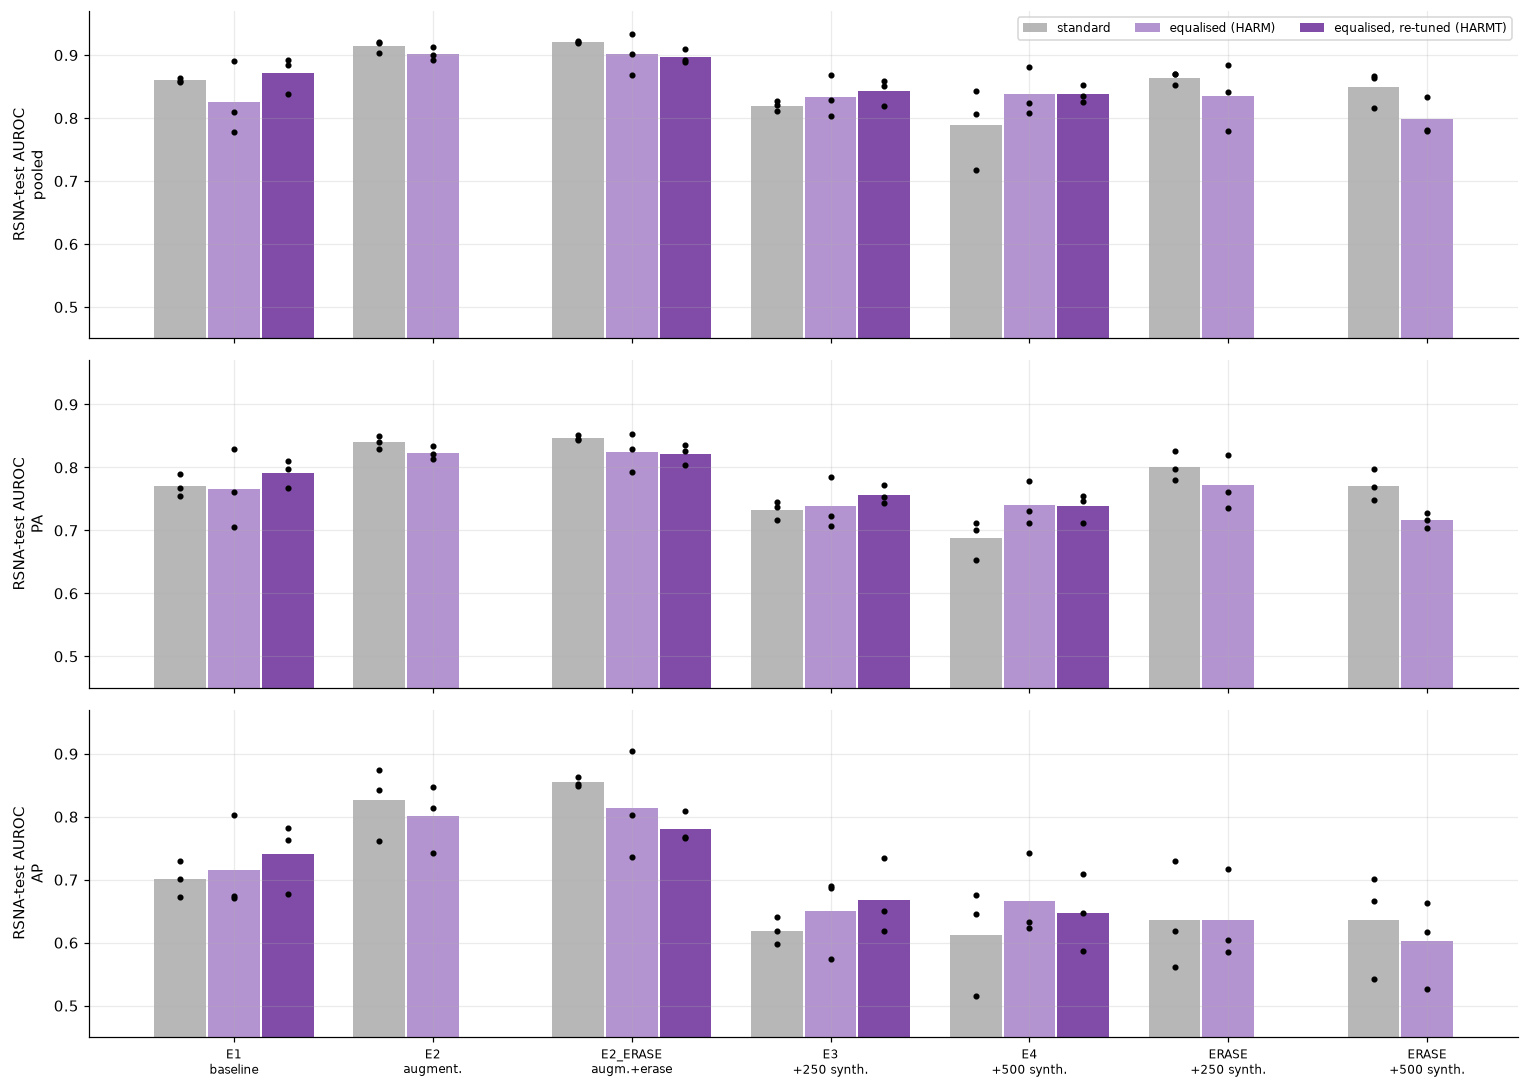

In [14]:
PREP = {"standard": "", "equalised (HARM)": "_HARM", "equalised, re-tuned (HARMT)": "_HARMT"}
PCOL = {"standard": "0.6", "equalised (HARM)": "tab:purple", "equalised, re-tuned (HARMT)": "indigo"}
BASES = {"E1": "E1", "E2": "E2", "E2_ERASE": "E2_ERASE", "E3": "E3_sd_lora", "E4": "E4_sd_lora",
         "ERASE_SYN250": "ERASE_SYN250_sd_lora", "ERASE_SYN500": "ERASE_SYN500_sd_lora"}
LAB6 = {"E1": "E1\nbaseline", "E2": "E2\naugment.", "E2_ERASE": "E2_ERASE\naugm.+erase", "E3": "E3\n+250 synth.", "E4": "E4\n+500 synth.",
        "ERASE_SYN250": "ERASE\n+250 synth.", "ERASE_SYN500": "ERASE\n+500 synth."}
hr = pd.DataFrame([dict(r, base=b_, preprocessing=pp) for b_, e in BASES.items() for pp, suf in PREP.items() for r in b_test_metrics(e + suf)])
display(hr.groupby(["base", "preprocessing"])[["pooled", "PA", "AP"]].agg(["mean", "count"]).reindex(
    [(b_, pp) for b_ in BASES for pp in PREP if ((hr.base == b_) & (hr.preprocessing == pp)).any()]).round(3))
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, k in zip(axes, ["pooled", "PA", "AP"]):
    for i, b_ in enumerate(BASES):
        for j, pp in enumerate(PREP):
            v = hr[(hr.base == b_) & (hr.preprocessing == pp)][k]
            if len(v):
                x = i + (j - 1) * 0.27
                ax.bar(x, v.mean(), 0.26, color=PCOL[pp], alpha=0.7, label=pp if i == 0 else None)
                ax.scatter([x] * len(v), v, color="k", s=9, zorder=3)
    ax.set_ylabel(f"RSNA-test AUROC\n{k}"); ax.set_ylim(0.45, 0.97)
axes[-1].set_xticks(range(len(BASES)), [LAB6[b_] for b_ in BASES], fontsize=8); axes[0].legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig(FIG / "synth_harmonize_training.png", bbox_inches="tight"); plt.show()

Ensemble Δ with patient-clustered bootstrap 95% CI for the comparisons that matter (`compare_harmt.csv`):

In [15]:
ch = pd.read_csv(SP / "compare_harmt.csv")
display(ch[["from", "to", "eval", "auroc_from", "auroc_to", "delta_ensemble", "ci_lo", "ci_hi", "n_seeds"]].round(3))

,from,to,eval,auroc_from,auroc_to,delta_ensemble,ci_lo,ci_hi,n_seeds
0,E1,E1_HARMT,rsna-test,0.880,0.891,0.012,0.008,0.016,3
1,E1,E1_HARMT,rsna-test&view=AP,0.747,0.776,0.028,0.017,0.040,3
2,E1,E1_HARMT,rsna-test&view=PA,0.791,0.811,0.020,0.008,0.031,3
3,E1_HARM,E1_HARMT,rsna-test,0.866,0.891,0.025,0.021,0.029,3
4,E1_HARM,E1_HARMT,rsna-test&view=AP,0.763,0.776,0.012,0.000,0.024,3
5,E1_HARM,E1_HARMT,rsna-test&view=PA,0.802,0.811,0.009,0.001,0.016,3
6,E2_ERASE,E2_ERASE_HARMT,rsna-test,0.930,0.912,-0.018,-0.021,-0.014,3
7,E2_ERASE,E2_ERASE_HARMT,rsna-test&view=AP,0.884,0.817,-0.067,-0.078,-0.055,3
8,E2_ERASE,E2_ERASE_HARMT,rsna-test&view=PA,0.859,0.842,-0.018,-0.027,-0.008,3
9,E1_HARMT,E3_sd_lora_HARMT,rsna-test,0.891,0.862,-0.030,-0.033,-0.027,3


**Reading.** With hyper-parameters tuned for it, equalised preprocessing improves the un-augmented baseline slightly (E1 0.880 → 0.891),
and synthetic images still cost 0.030 / 0.038 on top of it, about two thirds of the penalty under standard preprocessing. With
augmentation, equalisation does not weaken the penalty at all: +250 / +500 synthetic images cost 0.065 / 0.109 (squash: 0.055 / 0.060).
Equalisation removes part of what makes synthetic images harmful, never enough to make them useful.

## 7. Copies or new images? And which real images was the generator trained on?

For every synthetic image, its nearest real training image in ImageNet-EfficientNet-B0 feature space (cosine similarity). As references:
real validation images to their nearest *training* image (different patients), and synthetic images to their nearest *other* synthetic image.

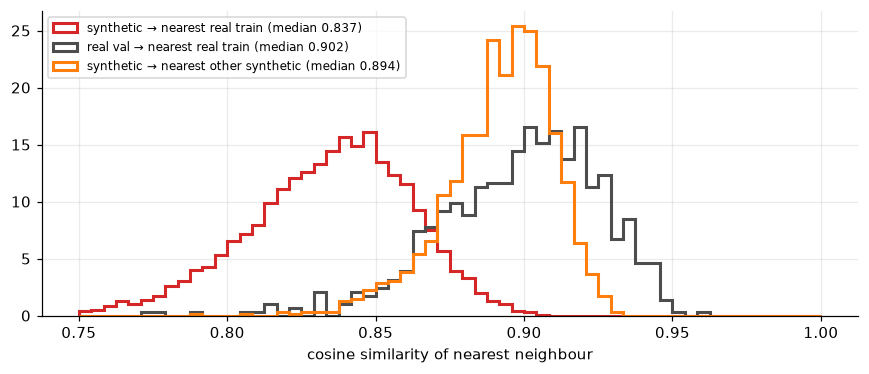

In [16]:
f = np.load(ROOT / "artifacts/cache/synth_probe_feats_imagenet.npz"); fs, ft, fv = f["syn"], f["trn"], f["val"]
s2t = (fs @ ft.T).max(1); v2t = (fv @ ft.T).max(1)
r = np.random.default_rng(0).choice(len(fs), 1500, replace=False); x = fs[r] @ fs.T; x[np.arange(len(r)), r] = -1; s2s = x.max(1)
fig, ax = plt.subplots(figsize=(8, 3.5))
for v, c, nm in [(s2t, "tab:red", "synthetic → nearest real train"), (v2t, "0.3", "real val → nearest real train"), (s2s, "tab:orange", "synthetic → nearest other synthetic")]:
    ax.hist(v, bins=60, range=(0.75, 1.0), density=True, histtype="step", lw=2, color=c, label=f"{nm} (median {np.median(v):.3f})")
ax.set_xlabel("cosine similarity of nearest neighbour"); ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(FIG / "synth_nn_similarity.png", bbox_inches="tight"); plt.show()

**How different are they as a population?** A linear classifier on the same generic features, asked to tell real from synthetic
(5-fold cross-validation), and a 2-D PCA projection of all images:

real vs synthetic, linear probe AUROC: 1.0000


normal vs pneumonia within synthetic: 0.9793


normal vs pneumonia within real: 0.9837


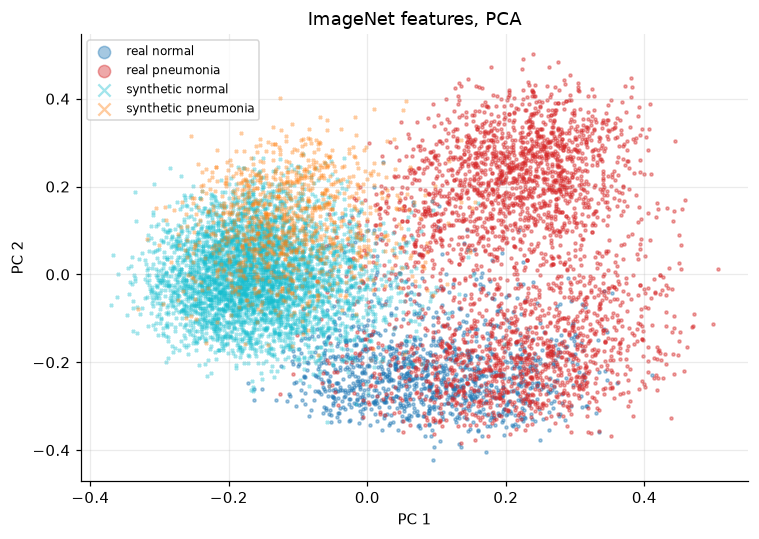

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.decomposition import PCA
X = np.vstack([fs, ft]); y = np.r_[np.ones(len(fs)), np.zeros(len(ft))]
p = cross_val_predict(LogisticRegression(max_iter=2000), X, y, cv=5, method="predict_proba")[:, 1]
print(f"real vs synthetic, linear probe AUROC: {roc_auc_score(y, p):.4f}")
for name, F_, Y_ in [("synthetic", fs, sl), ("real", ft, kl)]:
    pc = cross_val_predict(LogisticRegression(max_iter=2000), F_, Y_, cv=5, method="predict_proba")[:, 1]
    print(f"normal vs pneumonia within {name}: {roc_auc_score(Y_, pc):.4f}")
Z = PCA(2, random_state=0).fit_transform(X)
fig, ax = plt.subplots(figsize=(7, 5))
for (src, lab), c, m in [(("real", 0), "tab:blue", "o"), (("real", 1), "tab:red", "o"), (("synthetic", 0), "tab:cyan", "x"), (("synthetic", 1), "tab:orange", "x")]:
    sel = (y == (src == "synthetic")) & (np.r_[sl, kl] == lab)
    ax.scatter(Z[sel, 0], Z[sel, 1], s=4, alpha=0.4, c=c, marker=m, label=f"{src} {'pneumonia' if lab else 'normal'}")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(markerscale=4, fontsize=8); ax.set_title("ImageNet features, PCA")
plt.tight_layout(); plt.savefig(FIG / "synth_pca.png", bbox_inches="tight"); plt.show()

The five synthetic images **closest** to any real training image, next to that real image (the strongest memorisation candidates):

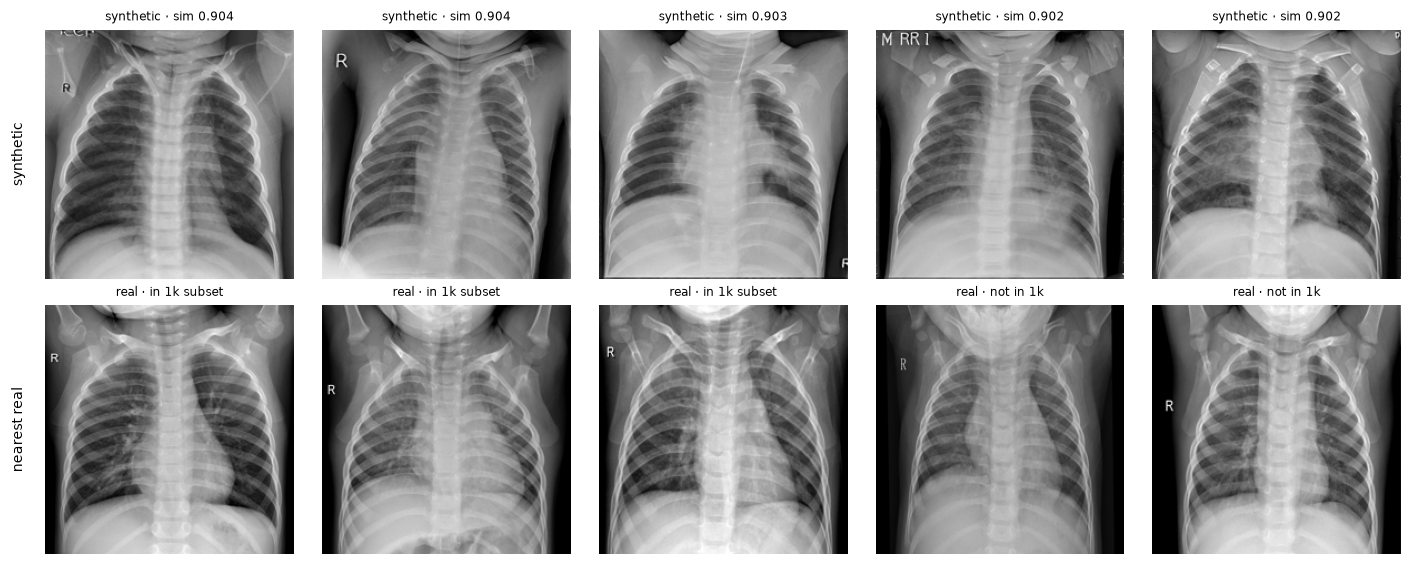

In [18]:
nn = pd.read_csv(SP / "nn_imagenet.csv").sort_values("nn_sim", ascending=False).head(5)
kpos = {iid: i for i, iid in enumerate(kt.df.image_id)}
rows = [[syn.images[np.array([pos[i]])][0, 0] for i in nn.image_id], [kt.images[np.array([kpos[i]])][0, 0] for i in nn.nn_image_id]]
titles = [[f"synthetic · sim {s:.3f}" for s in nn.nn_sim], [f"real · {'in 1k subset' if b else 'not in 1k'}" for b in nn.nn_in_1k]]
grid(rows, titles, ["synthetic", "nearest real"], size=2.6); plt.savefig(FIG / "synth_nn_pairs.png", bbox_inches="tight"); plt.show()

**Which training set?** If the LoRA was trained only on the classifier's 1,000-image subset (*strict*), synthetic images should resemble
those images more than the other ~3,000 training images.

In [19]:
nn = pd.read_csv(SP / "nn_imagenet.csv")
base = kt.df.assign(label=kl).groupby("label").subset_1k.mean()
tab = pd.DataFrame({"share of nearest neighbours in 1k subset": nn.groupby("label").nn_in_1k.mean(), "base rate in train split": base})
tab.index = ["normal", "pneumonia"]; display(tab.round(3))

,share of nearest neighbours in 1k subset,base rate in train split
normal,0.270,0.433
pneumonia,0.186,0.170


## 8. Does *more* synthetic data help?

The generator can produce any number of images, so the obvious objection is that 250 or 500 is too few. E1's 1,000 real images plus
250, 500, 1,000 or 2,000 synthetic images (2,000 = every synthetic pneumonia image plus 1,000 normals, the largest balanced set), and a
model trained on the 2,000 synthetic images **only**. No augmentation, EfficientNet-B0. Green: the same number of *real* images instead.

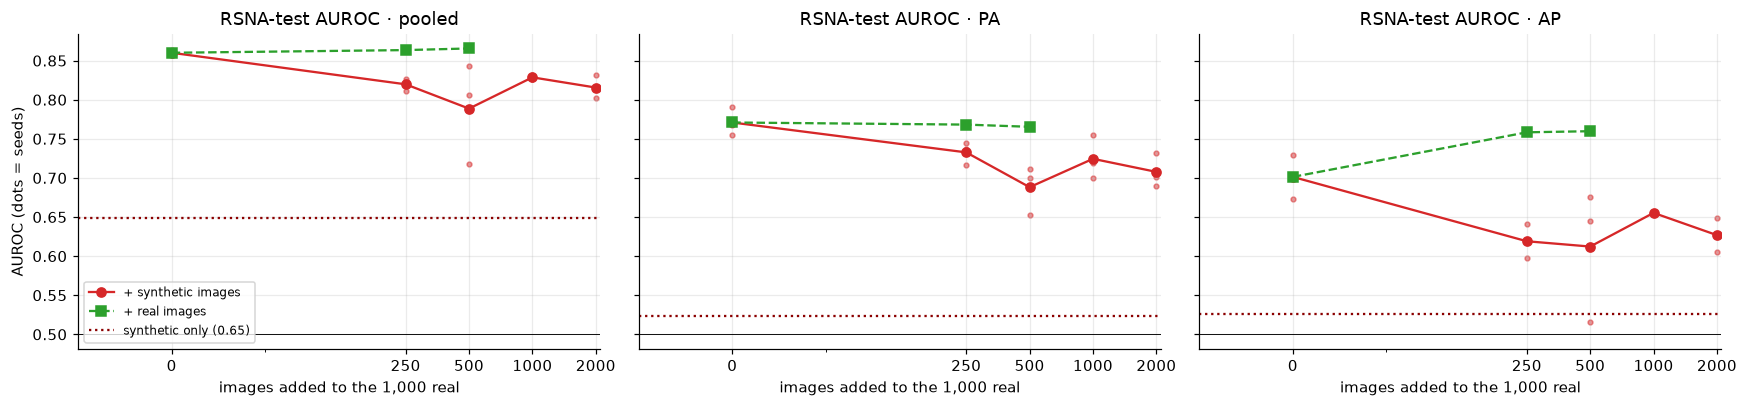

pooled           PA           AP       Kermany test
                 mean count   mean count   mean count             
n                                                                 
0               0.860   3.0  0.771   3.0  0.701   3.0        0.937
250             0.820   3.0  0.733   3.0  0.619   3.0        0.902
500             0.789   3.0  0.688   3.0  0.612   3.0        0.894
1000            0.829   3.0  0.724   3.0  0.655   3.0        0.908
2000            0.816   3.0  0.708   3.0  0.627   3.0        0.915
synthetic only  0.649   3.0  0.523   3.0  0.526   3.0        0.878

In [20]:
DOSE = {0: "E1", 250: "E3_sd_lora", 500: "E4_sd_lora", 1000: "SYN1000_sd_lora", 2000: "SYN2000_sd_lora"}
dr = pd.DataFrame([dict(r, n=n) for n, e in DOSE.items() for r in b_test_metrics(e)])
so = pd.DataFrame(b_test_metrics("SYN_ONLY_sd_lora"))
rr = pd.DataFrame([dict(r, n=n) for n, e in {250: "R25", 500: "R50"}.items() for r in b_test_metrics(e)])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, k in zip(axes, ["pooled", "PA", "AP"]):
    m = dr.groupby("n")[k].mean()
    ax.plot(m.index, m.values, "o-", color="tab:red", label="+ synthetic images"); ax.scatter(dr.n, dr[k], color="tab:red", s=10, alpha=0.5)
    mr = rr.groupby("n")[k].mean()
    ax.plot([0, *mr.index], [m.loc[0], *mr.values], "s--", color="tab:green", label="+ real images")
    ax.axhline(so[k].mean(), color="darkred", ls=":", label=f"synthetic only ({so[k].mean():.2f})")
    ax.axhline(0.5, color="k", lw=0.6)
    ax.set_xscale("symlog", linthresh=250); ax.set_xticks(list(DOSE), [str(n) for n in DOSE])
    ax.set_xlabel("images added to the 1,000 real"); ax.set_title(f"RSNA-test AUROC · {k}")
axes[0].set_ylabel("AUROC (dots = seeds)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "synth_dose_response.png", bbox_inches="tight"); plt.show()

def kermany_test(exp):
    return [roc_auc_score(d.label, d.prob) for seed in range(3)
            if (p := RUNS_DIR / exp / ARCH / f"seed{seed}" / "preds_A_test.csv").exists() for d in [pd.read_csv(p)]]
tab = dr.groupby("n")[["pooled", "PA", "AP"]].agg(["mean", "count"])
tab.loc["synthetic only"] = so[["pooled", "PA", "AP"]].agg(["mean", "count"]).T.stack().values
tab["Kermany test"] = [np.mean(kermany_test(e)) for e in [*DOSE.values(), "SYN_ONLY_sd_lora"]]
display(tab.round(3))

**Reading.** From 250 to 2,000 synthetic images (8×) the penalty stays between −0.04 and −0.065 with no trend: it is a fixed bias the synthetic images
introduce, not a dilution that more images would wash out. A model trained on synthetic images alone does well on the Kermany test set
but is at **chance on RSNA PA films**; its pooled AUROC is mostly recognising the view. What the generator encodes is Kermany's
appearance, not a notion of pneumonia that transfers.

## 9. The shortcut in real RSNA films, with nothing changed

§5 *induced* blur on healthy images. Here no image is changed: each labelled RSNA-test film's own sharpness (high-frequency energy),
contrast (central-crop SD), brightness and the patient's age are measured and related to each run's seed-averaged logit
(`scripts/synth_probe/natural_quality.py` → `rsna_quality_scores.csv`).

**Quality weight relative to opacity weight.** Per view, the standardised logit is regressed on label, z(sharpness), z(contrast),
z(brightness) and z(age); the plot shows −β(sharpness) / β(label): how many "units of opacity" one SD of blur is worth (95% bootstrap
CI, 300 resamples). 0 = the model ignores sharpness, 1 = one SD of blur moves the score as much as an opacity does.

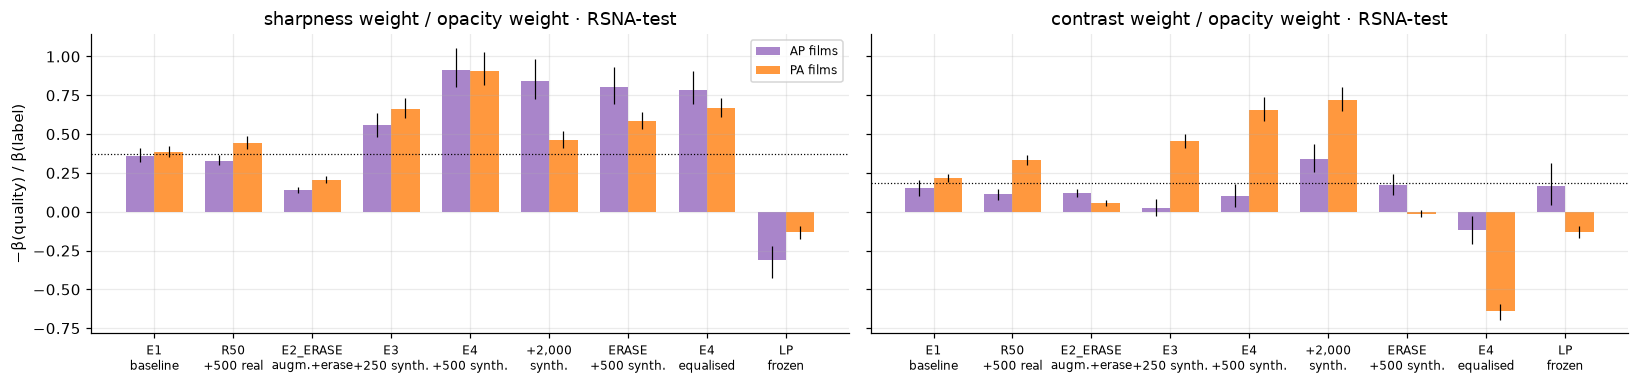

sharp       contrast      
view                    AP    PA       AP    PA
run                                            
E1                    0.36  0.39     0.15  0.22
R50                   0.33  0.45     0.11  0.33
E2_ERASE              0.14  0.20     0.12  0.06
E3_sd_lora            0.56  0.66     0.03  0.46
E4_sd_lora            0.91  0.90     0.10  0.65
SYN2000_sd_lora       0.84  0.46     0.34  0.72
ERASE_SYN500_sd_lora  0.80  0.59     0.17 -0.01
E4_sd_lora_HARMT      0.78  0.67    -0.12 -0.64
LP                   -0.31 -0.13     0.16 -0.13

In [21]:
qs = pd.read_csv(SP / "rsna_quality_scores.csv", dtype={"patient_id": str})
qt = qs[qs.label.notna() & (qs.b_role == "test")].reset_index(drop=True)
Zq = {c: ((qt[c] - qt[c].mean()) / qt[c].std()).values for c in ["hf_energy", "std", "mean", "age"]}
XQ = np.column_stack([np.ones(len(qt)), qt.label.values, Zq["hf_energy"], Zq["std"], Zq["mean"], Zq["age"]])

def quality_ratio(runs, n_boot=300, rng=np.random.default_rng(0)):
    out = []
    for v in ["AP", "PA"]:
        idx = np.where(qt.view == v)[0]
        for r in runs:
            if f"logit_{r}" not in qt:
                continue
            y = qt[f"logit_{r}"].values; y = (y - y[idx].mean()) / y[idx].std()
            f = lambda ii: (lambda b: (-b[2] / b[1], -b[3] / b[1]))(np.linalg.lstsq(XQ[ii], y[ii], rcond=None)[0])
            est, bs = f(idx), np.array([f(rng.choice(idx, len(idx))) for _ in range(n_boot)])
            out.append(dict(run=r, view=v, sharp=est[0], s_lo=np.percentile(bs[:, 0], 2.5), s_hi=np.percentile(bs[:, 0], 97.5),
                            contrast=est[1], c_lo=np.percentile(bs[:, 1], 2.5), c_hi=np.percentile(bs[:, 1], 97.5)))
    return pd.DataFrame(out)

def ratio_plot(qr, runs, names, fname, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), sharey=True)
    for ax, k, lo, hi, lab in [(axes[0], "sharp", "s_lo", "s_hi", "sharpness"), (axes[1], "contrast", "c_lo", "c_hi", "contrast")]:
        for j, (v, c) in enumerate([("AP", "tab:purple"), ("PA", "tab:orange")]):
            d = qr[qr.view == v].set_index("run").reindex(runs)
            x = np.arange(len(runs)) + (j - 0.5) * 0.36
            ax.bar(x, d[k], 0.36, color=c, alpha=0.8, label=f"{v} films")
            ax.errorbar(x, d[k], yerr=[d[k] - d[lo], d[hi] - d[k]], fmt="none", ecolor="k", lw=0.8)
        ax.axhline(qr[(qr.run == "E1")][k].mean(), color="k", ls=":", lw=0.8)
        ax.set_xticks(range(len(runs)), [names.get(r, r) for r in runs], fontsize=8)
        ax.set_title(f"{lab} weight / opacity weight · {title}")
    axes[0].set_ylabel("−β(quality) / β(label)"); axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(FIG / fname, bbox_inches="tight"); plt.show()

RUNS9 = ["E1", "R50", "E2_ERASE", "E3_sd_lora", "E4_sd_lora", "SYN2000_sd_lora", "ERASE_SYN500_sd_lora", "E4_sd_lora_HARMT", "LP"]
NAMES9 = {**NAMES, "E4_sd_lora_HARMT": "E4\nequalised", "LP": "LP\nfrozen"}
qr9 = quality_ratio(RUNS9)
ratio_plot(qr9, RUNS9, NAMES9, "synth_quality_ratio.png", "RSNA-test")
display(qr9.pivot(index="run", columns="view", values=["sharp", "contrast"]).reindex(RUNS9).round(2))

**Reading.** The baseline already weighs one SD of blur at about a third of an opacity (E1 0.36 / 0.39): the rule is learned from
Kermany. +500 synthetic images raise it to 0.9, so blur moves an E4 model almost as much as an opacity. +500 *real* images (R50) leave it
unchanged, and augmentation (E2_ERASE) halves it. Synthetic images also add **contrast** weight on PA films. Equalised
preprocessing does not undo the sharpness increase. LP (frozen ImageNet features) shows no positive quality weight: the reliance is
learned during fine-tuning.

**Where the penalty lands.** RSNA-test AUROC within thirds of film sharpness, per view:

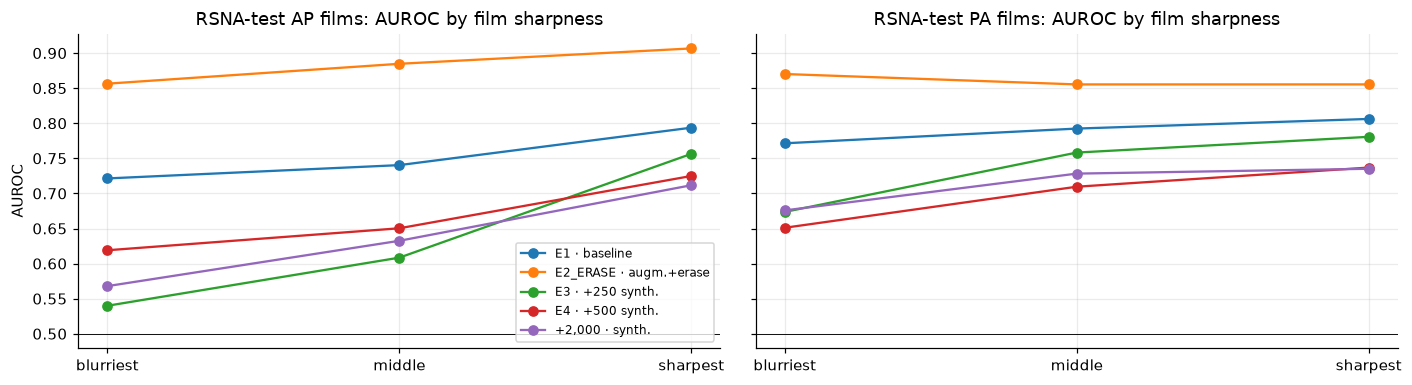

view                   AP                        PA                
third           blurriest middle sharpest blurriest middle sharpest
run                                                                
E1                  0.721  0.740    0.794     0.771  0.792    0.806
E2_ERASE            0.856  0.885    0.907     0.870  0.855    0.855
E3_sd_lora          0.540  0.608    0.756     0.674  0.758    0.781
E4_sd_lora          0.619  0.650    0.725     0.651  0.710    0.737
SYN2000_sd_lora     0.568  0.632    0.712     0.676  0.728    0.735

opacity prevalence per third: {('AP', 'blurriest'): 0.82, ('AP', 'middle'): 0.72, ('AP', 'sharpest'): 0.73, ('PA', 'blurriest'): 0.2, ('PA', 'middle'): 0.15, ('PA', 'sharpest'): 0.14}


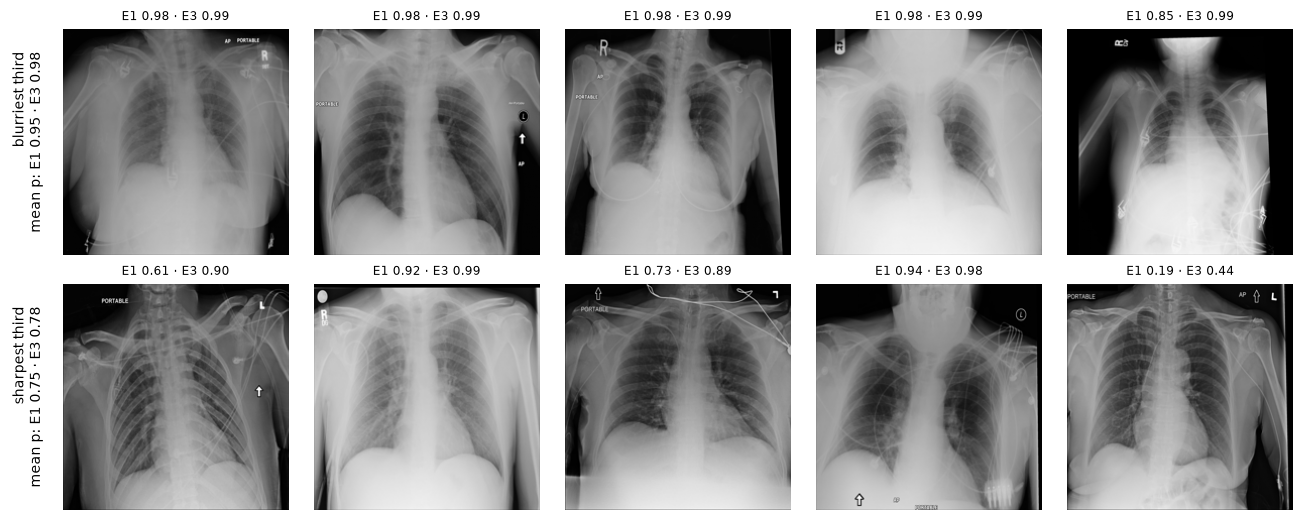

In [22]:
TERT_RUNS = ["E1", "E2_ERASE", "E3_sd_lora", "E4_sd_lora", "SYN2000_sd_lora"]
rows = []
for v in ["AP", "PA"]:
    g = qt[qt.view == v].copy(); g["third"] = pd.qcut(g.hf_energy, 3, labels=["blurriest", "middle", "sharpest"])
    for r in TERT_RUNS:
        for t, h in g.groupby("third", observed=True):
            rows.append(dict(view=v, run=r, third=t, auroc=roc_auc_score(h.label, h[f"logit_{r}"]), prev=h.label.mean()))
tt = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, v in zip(axes, ["AP", "PA"]):
    for r in TERT_RUNS:
        d = tt[(tt.view == v) & (tt.run == r)]
        ax.plot(d.third.astype(str), d.auroc, "o-", label=SHORT.get(r, r))
    ax.axhline(0.5, color="k", lw=0.6); ax.set_title(f"RSNA-test {v} films: AUROC by film sharpness")
axes[0].set_ylabel("AUROC"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "synth_auroc_by_sharpness.png", bbox_inches="tight"); plt.show()
display(tt.pivot_table(index="run", columns=["view", "third"], values="auroc", observed=True).reindex(TERT_RUNS).round(3))
print("opacity prevalence per third:", tt.drop_duplicates(["view", "third"]).set_index(["view", "third"]).prev.round(2).to_dict())

# healthy AP films from the blurriest vs the sharpest third, with E1 and E3 pneumonia probabilities
h = qt[(qt.view == "AP") & (qt.label == 0)].copy()
h["third"] = pd.qcut(h.hf_energy, 3, labels=["blurriest", "middle", "sharpest"])
pr = lambda x: 1 / (1 + np.exp(-x))
pos = pd.Series(np.arange(len(rs.df)), index=rs.df["image_id"].values)
rows_i, rows_t, labs = [], [], []
for t in ["blurriest", "sharpest"]:
    g = h[h.third == t]
    s5 = g.sample(5, random_state=0)
    rows_i.append([np.squeeze(rs.images[pos[i]]) for i in s5.image_id])
    rows_t.append([f"E1 {pr(a):.2f} · E3 {pr(c):.2f}" for a, c in zip(s5.logit_E1, s5.logit_E3_sd_lora)])
    labs.append(f"{t} third\nmean p: E1 {pr(g.logit_E1).mean():.2f} · E3 {pr(g.logit_E3_sd_lora).mean():.2f}")
grid(rows_i, rows_t, labs, size=2.4)
plt.savefig(FIG / "synth_blurry_vs_sharp_normals.png", bbox_inches="tight"); plt.show()

**Reading.** The penalty is concentrated in the **lowest-quality films**. On the blurriest third of AP films E3 is close to chance
(0.54, against 0.72 for E1), while on the sharpest third it loses little. Opacity prevalence barely differs across thirds, so this is not
a prevalence artefact. Blurry AP films are typically portable bedside images of the sickest patients, which is exactly where a
pneumonia classifier would be used; the pooled AUROC hides this. The image grid shows healthy AP films from both ends: the blurry ones get higher
pneumonia probabilities, more so from E3.

**Age**, a second real-data shortcut. Among healthy RSNA films, score vs patient age (Spearman ρ):

In [23]:
from scipy.stats import spearmanr
hn = qt[qt.label == 0]
AGE_RUNS = ["E1", "R50", "E2_ERASE", "E3_sd_lora", "E4_sd_lora", "LP"]
display(pd.DataFrame({v: {SHORT.get(r, r): spearmanr(hn[hn.view == v].age, hn[hn.view == v][f"logit_{r}"]).statistic
                          for r in AGE_RUNS} for v in ["AP", "PA"]}).round(2))
print("AUROC of age for opacity (RSNA-test):", {v: round(roc_auc_score(g.label, g.age), 3) for v, g in qt.groupby("view")})

,AP,PA
E1 · baseline,0.25,0.34
R50 · +500 real,0.20,0.14
E2_ERASE · augm.+erase,0.21,0.31
E3 · +250 synth.,0.22,0.26
E4 · +500 synth.,0.19,0.23
LP,0.05,0.10


AUROC of age for opacity (RSNA-test): {'AP': 0.548, 'PA': 0.543}


**Reading.** Every fine-tuned model scores older healthy patients higher, synthetic data or not, although age itself barely predicts
opacity. Kermany consists of young children, so adult ageing (more tissue, degenerative change) reads as disease. This is a
real-data shortcut the synthetic images neither create nor fix.

## 10. Choosing *which* synthetic images to add

If the harm comes from the synthetic images' quality profile, choosing the synthetic subset by quality should change it.
`scripts/synth_probe/quality_select.py` re-ranks the same 5,000 images: **matched** = greedy (pneumonia, normal) pairs with the
nearest sharpness and contrast, so quality carries no label information inside the subset; **counter** = sharpest, most contrasty
pneumonia and softest, flattest normals first, so the cue points the other way. E3/E4 are retrained with each ranking.

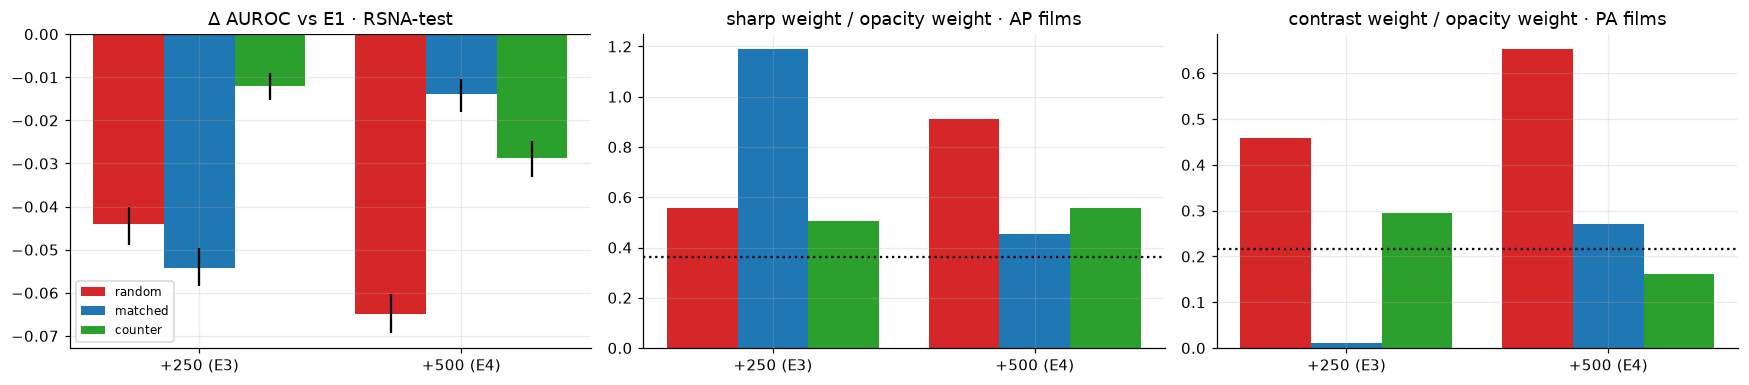

,selection,n,run,delta,lo,hi
0,random,250,E3_sd_lora,-0.044,-0.049,-0.040
1,random,500,E4_sd_lora,-0.065,-0.069,-0.060
2,matched,250,E3_sd_lora_QM,-0.054,-0.058,-0.050
3,matched,500,E4_sd_lora_QM,-0.014,-0.018,-0.010
4,counter,250,E3_sd_lora_QC,-0.012,-0.015,-0.009
5,counter,500,E4_sd_lora_QC,-0.029,-0.033,-0.025


In [24]:
from cxr.analysis import compare
SEL = {"random": "", "matched": "_QM", "counter": "_QC"}
rows = []
for sel, suf in SEL.items():
    for n, e in [(250, "E3"), (500, "E4")]:
        r = compare("E1", f"{e}_sd_lora{suf}", ARCH, "B_external:label@b_role=test", n_boot=500)
        rows.append(dict(selection=sel, n=n, run=f"{e}_sd_lora{suf}", delta=r["delta_ensemble"], lo=r["ci_lo"], hi=r["ci_hi"]))
sel = pd.DataFrame(rows)
qr10 = quality_ratio(["E1"] + sel.run.tolist())
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for j, (s, c) in enumerate(zip(SEL, ["tab:red", "tab:blue", "tab:green"])):
    d = sel[sel.selection == s]; x = np.arange(2) + (j - 1) * 0.27
    axes[0].bar(x, d.delta, 0.27, color=c, label=s); axes[0].errorbar(x, d.delta, yerr=[d.delta - d.lo, d.hi - d.delta], fmt="none", ecolor="k")
    for ax, k in [(axes[1], "sharp"), (axes[2], "contrast")]:
        q = qr10[qr10.view == ("AP" if k == "sharp" else "PA")].set_index("run").reindex(d.run)
        ax.bar(x, q[k].values, 0.27, color=c, label=s)
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_title("Δ AUROC vs E1 · RSNA-test"); axes[0].legend(fontsize=8)
for ax, k, v in [(axes[1], "sharp", "AP"), (axes[2], "contrast", "PA")]:
    ax.axhline(qr10[(qr10.run == "E1") & (qr10.view == v)][k].item(), color="k", ls=":", label="E1")
    ax.set_title(f"{k} weight / opacity weight · {v} films")
for ax in axes:
    ax.set_xticks([0, 1], ["+250 (E3)", "+500 (E4)"])
plt.tight_layout(); plt.savefig(FIG / "synth_quality_selection.png", bbox_inches="tight"); plt.show()
display(sel.round(3))

**Reading.** Choosing the synthetic images by quality removes most of the penalty in three of four cases (best −0.012 / −0.014, against
−0.044 / −0.065 for random selection), and it reliably removes the extra **contrast** weight on PA films. This is the most direct
evidence that the harm comes from the *quality profile* of the synthetic images, not from synthetic images as such. But no selection
**helps**: the best ones only reach E1. Sharpness weight is not reduced consistently, because the sharpness rule is inherited from the
1,000 real Kermany images the synthetic ones are added to. Seed spread is large, so the ordering of matched vs counter is not stable.

## 11. Can the training loss make the model ignore the shortcut?

Instead of changing the data, change the objective. Four losses (`cxr/engine.py`, `LOSSES`; `scripts/run.py --loss`), each on E1 and on
E3 (+250 synthetic), EfficientNet-B0, 3 seeds, BCE-tuned hyper-parameters; validation and early stopping stay plain BCE.

| Loss | Idea |
|---|---|
| `focal` (γ = 2) | down-weight examples that are already classified correctly |
| `gce` (q = 0.7) | generalised cross-entropy: bounded, robust to label noise (synthetic labels are partly noise, §3) |
| `qdro` (η = 0.01) | online group DRO over label × softer/sharper half of the training images |
| `qcons` (λ = 1) | BCE + squared change of the logit under random blur (σ 0.5–2) and contrast reduction (×0.6–1) |

Comparisons: `scripts/synth_probe/loss_compare.py` → `compare_losses.csv`.

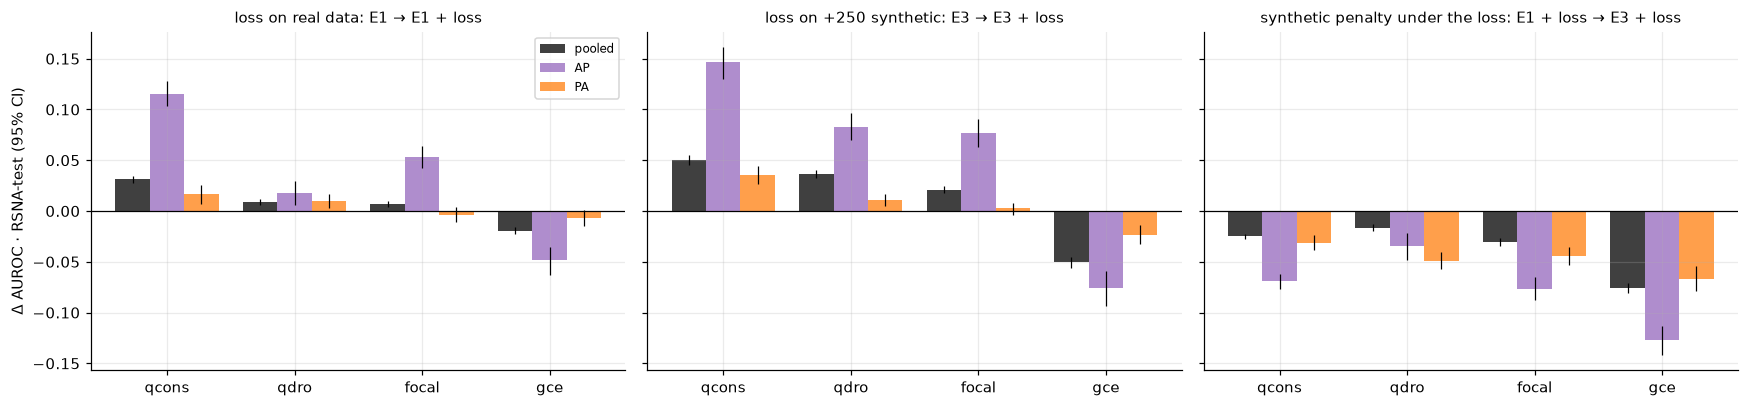

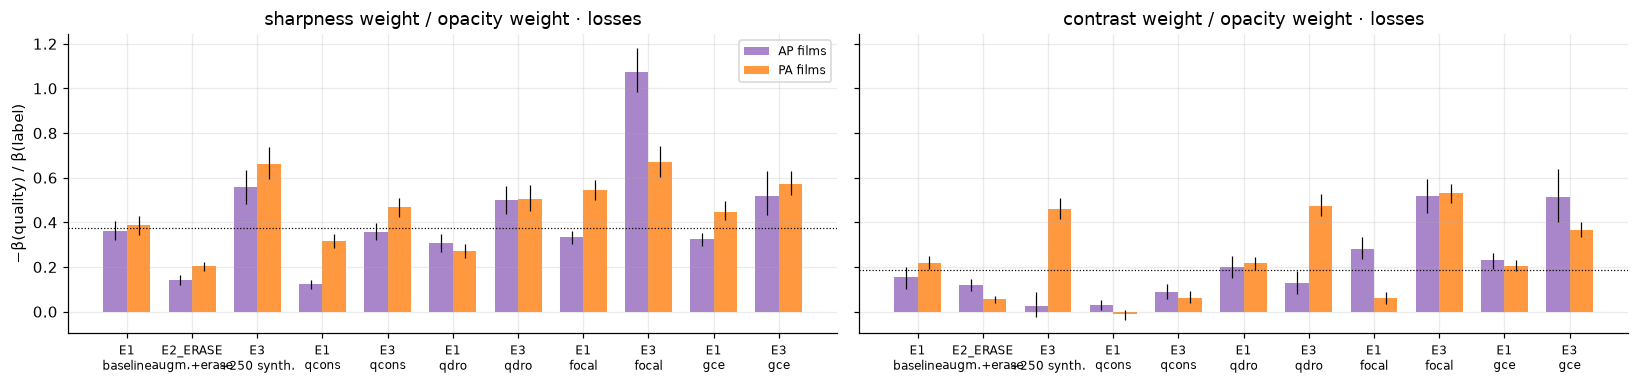

/tmp/ipykernel_128406/3727256581.py:27: PerformanceWarning: indexing past lexsort depth may impact performance.
  display(cl.set_index(["from", "to"]).loc[[k for k in KEY if k in cl.set_index(["from", "to"]).index]]
/tmp/ipykernel_128406/3727256581.py:27: PerformanceWarning: indexing past lexsort depth may impact performance.
  display(cl.set_index(["from", "to"]).loc[[k for k in KEY if k in cl.set_index(["from", "to"]).index]]
/tmp/ipykernel_128406/3727256581.py:27: PerformanceWarning: indexing past lexsort depth may impact performance.
  display(cl.set_index(["from", "to"]).loc[[k for k in KEY if k in cl.set_index(["from", "to"]).index]]
/tmp/ipykernel_128406/3727256581.py:27: PerformanceWarning: indexing past lexsort depth may impact performance.
  display(cl.set_index(["from", "to"]).loc[[k for k in KEY if k in cl.set_index(["from", "to"]).index]]
/tmp/ipykernel_128406/3727256581.py:27: PerformanceWarning: indexing past lexsort depth may impact performance.
  display(cl.set_index([

,from,to,eval,auroc_from,auroc_to,delta_ensemble,ci_lo,ci_hi,n_seeds
0,E1,E1_LQCONS,rsna-test,0.880,0.911,0.031,0.028,0.035,3
1,E1,E1_LQCONS,rsna-test&view=AP,0.747,0.863,0.116,0.104,0.128,3
2,E1,E1_LQCONS,rsna-test&view=PA,0.791,0.807,0.016,0.007,0.025,3
3,E2,E1_LQCONS,rsna-test,0.930,0.911,-0.020,-0.023,-0.017,3
4,E2,E1_LQCONS,rsna-test&view=AP,0.881,0.863,-0.018,-0.027,-0.010,3
5,E2,E1_LQCONS,rsna-test&view=PA,0.858,0.807,-0.050,-0.059,-0.041,3
6,E2_ERASE,E2_ERASE_LQCONS,rsna-test,0.930,0.930,0.000,-0.002,0.002,3
7,E2_ERASE,E2_ERASE_LQCONS,rsna-test&view=AP,0.884,0.884,0.001,-0.006,0.008,3
8,E2_ERASE,E2_ERASE_LQCONS,rsna-test&view=PA,0.859,0.861,0.002,-0.004,0.008,3
9,E1,E3_sd_lora_LQCONS,rsna-test,0.880,0.886,0.006,0.003,0.010,3


,arch,from,to,eval,auroc_from,auroc_to,delta_ensemble,ci_lo,ci_hi
69,densenet121,E1,E1_LQCONS,rsna-test,0.902,0.907,0.005,0.003,0.008
70,densenet121,E1,E1_LQCONS,rsna-test&view=AP,0.794,0.823,0.029,0.018,0.040
71,densenet121,E1,E1_LQCONS,rsna-test&view=PA,0.826,0.832,0.006,-0.001,0.012
72,vit_small,E1,E1_LQCONS,rsna-test,0.842,0.883,0.040,0.036,0.045
73,vit_small,E1,E1_LQCONS,rsna-test&view=AP,0.704,0.811,0.107,0.096,0.120
74,vit_small,E1,E1_LQCONS,rsna-test&view=PA,0.727,0.770,0.043,0.032,0.054
75,swin_tiny,E1,E1_LQCONS,rsna-test,0.867,0.873,0.006,0.002,0.010
76,swin_tiny,E1,E1_LQCONS,rsna-test&view=AP,0.682,0.762,0.079,0.064,0.093
77,swin_tiny,E1,E1_LQCONS,rsna-test&view=PA,0.792,0.787,-0.005,-0.014,0.004
78,swin_tiny,E3_sd_lora,E3_sd_lora_LQCONS,rsna-test,0.826,0.865,0.039,0.034,0.044


In [25]:
cl = pd.read_csv(SP / "compare_losses.csv")
cl = cl[cl.arch == ARCH]
LOSS = {"LQCONS": "qcons", "LQDRO": "qdro", "LFOCAL": "focal", "LGCE": "gce"}
def dget(a, b, ev="rsna-test"):
    r = cl[(cl["from"] == a) & (cl["to"] == b) & (cl["eval"] == ev)]
    return r.iloc[0] if len(r) else None
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
panels = [("loss on real data: E1 → E1 + loss", lambda l: ("E1", f"E1_{l}")),
          ("loss on +250 synthetic: E3 → E3 + loss", lambda l: ("E3_sd_lora", f"E3_sd_lora_{l}")),
          ("synthetic penalty under the loss: E1 + loss → E3 + loss", lambda l: (f"E1_{l}", f"E3_sd_lora_{l}"))]
for ax, (title, pair) in zip(axes, panels):
    for j, (ev, c) in enumerate([("rsna-test", "k"), ("rsna-test&view=AP", "tab:purple"), ("rsna-test&view=PA", "tab:orange")]):
        x = np.arange(len(LOSS)) + (j - 1) * 0.27
        d = [dget(*pair(l), ev) for l in LOSS]
        y = np.array([r.delta_ensemble for r in d]); lo = np.array([r.ci_lo for r in d]); hi = np.array([r.ci_hi for r in d])
        ax.bar(x, y, 0.27, color=c, alpha=0.75, label=ev.replace("rsna-test&view=", "").replace("rsna-test", "pooled"))
        ax.errorbar(x, y, yerr=[y - lo, hi - y], fmt="none", ecolor="k", lw=0.8)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(LOSS)), LOSS.values()); ax.set_title(title, fontsize=10)
axes[0].set_ylabel("Δ AUROC · RSNA-test (95% CI)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "synth_losses.png", bbox_inches="tight"); plt.show()

RUNS11 = ["E1", "E2_ERASE", "E3_sd_lora"] + [f"{e}_{l}" for l in LOSS for e in ["E1", "E3_sd_lora"]]
NAMES11 = {**NAMES, **{f"E1_{l}": f"E1\n{n}" for l, n in LOSS.items()}, **{f"E3_sd_lora_{l}": f"E3\n{n}" for l, n in LOSS.items()}}
ratio_plot(quality_ratio(RUNS11), RUNS11, NAMES11, "synth_losses_quality_ratio.png", "losses")
KEY = [("E1", "E1_LQCONS"), ("E2", "E1_LQCONS"), ("E2_ERASE", "E2_ERASE_LQCONS"), ("E1", "E3_sd_lora_LQCONS"),
       ("E2_ERASE", "ERASE_SYN250_sd_lora"), ("E2_ERASE_LQCONS", "ERASE_SYN250_sd_lora_LQCONS"), ("E1", "E1_LQCONS03"), ("E1", "E1_LQCONS3")]
display(cl.set_index(["from", "to"]).loc[[k for k in KEY if k in cl.set_index(["from", "to"]).index]]
          .reset_index()[["from", "to", "eval", "auroc_from", "auroc_to", "delta_ensemble", "ci_lo", "ci_hi", "n_seeds"]].round(3))
other = pd.read_csv(SP / "compare_losses.csv").query("arch != @ARCH")
if len(other):
    display(other[["arch", "from", "to", "eval", "auroc_from", "auroc_to", "delta_ensemble", "ci_lo", "ci_hi"]].round(3))

**Reading.** Only the **quality-consistency loss** clearly helps: on real data alone it adds +0.031 (+0.116 on AP films) and cuts
the sharpness weight to the level of erasing augmentation (0.12 on AP). It acts as a loss-level form of augmentation: it still trails
E2 / E2_ERASE (0.911 vs 0.930), and on top of E2_ERASE it adds nothing (Δ 0.000). Group DRO and focal loss help only marginally, and
focal loss with synthetic data has the highest sharpness weight of any run. GCE under-fits and with synthetic data one seed stays at chance.
**No loss makes synthetic images help.** The synthetic penalty persists under every loss (−0.016 to −0.075). Even with
augmentation + qcons, adding 250 synthetic images costs −0.016.

## Insights

**1. The synthetic images hurt, and real images of the same quantity do not.** EfficientNet-B0, RSNA-test, 3-seed ensemble: E3
(+250 synthetic) lowers AUROC from 0.880 (E1) to 0.835 (Δ −0.044, 95% CI [−0.049, −0.040]); R25/R50 (the same number of *real* images)
stay at E1's level (0.889 / 0.879). The loss is largest on **AP films**: 0.747 (E1) → 0.647 (E3), while 250 extra real images *raise* it
to 0.803. Healthy AP films already score high under E1; synthetic training pushes them higher still, so they can no longer be told apart
from opacities.

**1b. Augmentation does not protect against them.** On top of E2_ERASE (the best real-data recipe, chosen on RSNA-dev), extra real images
change nothing (|Δ| ≤ 0.01) and extra synthetic images cost 0.02–0.06 for EfficientNet-B0, ViT-S and DenseNet-121 alike. On AP films
EfficientNet-B0 falls from 0.884 to 0.632, below the un-augmented E1.

**2. The generator learned a little pneumonia and a lot of Kermany.** Real-trained classifiers separate the synthetic classes
(AUROC 0.75–0.91), but the most robust models (E2_ERASE) give synthetic pneumonia a mean probability of only 0.28–0.54, against
0.96–0.98 for real pneumonia. The images they find convincing are the soft, hazy ones.

**3. The cue is image quality.** In Kermany, low sharpness and low contrast predict pneumonia (AUROC 0.87 / 0.75). The synthetic data
reproduces the sharpness cue (0.86) and amplifies the contrast cue (0.89). In RSNA both are near chance. Every synthetic image is
therefore a training example for a rule that fails externally.

**4. The models really use it (causal).** Mild blur (σ = 1) on healthy images raises the pneumonia score by +0.33 (Kermany) and +0.38
(RSNA PA) for E1, and by as much for R25/E3/E4: **"blurry = pneumonia" is learned from the real Kermany data**, not created by the
synthetic images. Augmentation raises the tolerance but does not remove the rule: E2_ERASE barely reacts to mild blur (+0.02 / +0.22),
yet under strong blur (σ = 2) it reacts the *most* of all models (+0.58 Kermany, +0.80 RSNA PA, from a lower clean score). Every model
treats a very blurry image as pneumonia. What synthetic training adds on top is **contrast** reliance: +0.41 vs +0.21 for E1 when contrast
is reduced on RSNA PA normals, while augmented models barely react (+0.06 / +0.07).

**5. This explains two earlier results.** It gives a mechanism for why E2/E2_ERASE transfer best (notebook 06: erasing helps as a
regulariser, not by moving attention), and why E2_ACQ's blur jitter was not enough on its own: the cue is partly image content, not
only acquisition.

**6. Preprocessing can remove some of it, not all.** Histogram equalisation removes most of the contrast cue (0.88 → 0.57) and part of the
sharpness cue. The rest survives any low-pass filter, so it is image content (probably patient age/size), which no preprocessing can
remove. Equalisation also makes **mean brightness** predictive in every set (Kermany 0.61 → 0.84, RSNA AP 0.56 → 0.80): because it works
externally too, this is most likely real opacity becoming visible, not a new shortcut. Retrained with equalised images and hyper-parameters
re-tuned for them, the baseline improves slightly (0.880 → 0.891) but **synthetic images still hurt** (−0.030 / −0.038), and with
augmentation they hurt even more than under standard preprocessing (−0.065 / −0.109). A first, untuned round had suggested the penalty
disappears; that came from a weak harmonised baseline.

**7. No memorisation, a separate style.** Synthetic images are much further from their nearest training image than real images of
*different* patients are (median 0.84 vs 0.90); even the closest synthetic image (0.904) is only as close as a typical real pair. Synthetic images resemble each other more than any real image. A linear probe on generic
ImageNet features tells real from synthetic **perfectly** (AUROC 1.000): to a network, the synthetic set is a domain of its own. Diversity
is limited: the 5,000 synthetic images map to only 658 distinct nearest real images (one real image is the nearest neighbour of 404). The nearest-neighbour test
gives no evidence that the LoRA was trained only on the 1k subset (the training set is still to be confirmed by the teammate).

**8. More synthetic data does not fix it.** From 250 to 2,000 synthetic images the penalty stays between −0.04 and −0.065, with no trend. A model
trained on synthetic images only reaches 0.85–0.91 on the Kermany test set but chance (0.50) on RSNA PA films. The harm is a fixed bias,
not a quantity problem: "generate as many as you want" buys nothing with this generator.

**9. The shortcut shows up in real external films.** With nothing changed, one SD of natural blur in an RSNA film is worth about a
third of an opacity to E1 (0.36 / 0.39 AP / PA) and almost a whole opacity to E4 (0.91 / 0.90); +500 real images leave it unchanged,
augmentation halves it. The penalty lands on the **blurriest films**: E3 is near chance (0.54) on the blurriest third of AP films,
the bedside images of the sickest patients. Separately, every fine-tuned model scores older healthy adults higher: an age shortcut
from a paediatric training set, independent of synthetic data.

**10. Choosing the synthetic images by quality makes them harmless, not useful.** Quality-matched or quality-counter subsets remove
most of the penalty (best −0.012 / −0.014) and the extra contrast reliance, which points directly at the quality profile as the cause.
None of them beats E1.

**11. A loss that penalises quality sensitivity works, but it does not rescue synthetic data.** The quality-consistency loss
(qcons) adds +0.031 on RSNA-test (+0.116 on AP films) to E1 and cuts its sharpness weight to E2_ERASE's level. It acts like
augmentation (E2_ERASE + qcons: +0.000) and stays just below it. Under every loss, adding synthetic images still costs 0.016–0.075;
with augmentation + qcons, the strongest synthetic configuration, it costs −0.016. Focal loss and group DRO help little, and GCE breaks
training.

**Consequence for the study.** Adding *synthetic images* from an unconstrained, class-conditional generator trained on a shortcut-laden
source does not add disease information. It adds more of the source's acquisition signature, and makes external performance worse.
Quality-aware selection (§10) and a quality-consistency loss (§11) make the synthetic images close to harmless, but in no
configuration do they beat the same training without them. The comparison bar is E2_ERASE, not E1.